# Kibernetska varnost – pregled podatkov in zasnova raziskave

**Delovno raziskovalno vprašanje:** Kateri dejavniki so povezani z razlikami v vrstah in ciljnih sektorjih javno dokumentiranih kibernetskih incidentov med državami ter kako se te razlike spreminjajo skozi čas?

Namen zvezka je pregled razpoložljivih podatkov, njihove kakovosti in raziskovalne izvedljivosti.

## 1. Raziskovalni okvir

### 1.1. Tema in raziskovalni problem

**Tema:** Kibernetska varnost. Osredotočamo se na javno dokumentirane incidente, njihove vrste, ciljne sektorje in razlike med državami.

### 1.2. Raziskovalna vprašanja

- *Kateri dejavniki so povezani z razlikami v vrstah in ciljnih sektorjih javno dokumentiranih kibernetskih incidentov med državami ter kako se te razlike spreminjajo skozi čas?*

### 1.3. Odločitveno vprašanje

Ideje: 

*Možnost A:* Katere vrste kibernetskih groženj naj izbrana država prednostno obravnava?

*Možnost B:* Katerim sektorjem naj izbrana država prednostno nameni preventivna sredstva?

## 2. Podatkovni viri in uvoz

### 2.1. Struktura projekta in knjižnice

Namestitev potrebnih paketov (po potrebi): `pip install pandas openpyxl matplotlib seaborn`

In [7]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

import re
import unicodedata


# Delovni imenik je notebooks/ , podatki so v ../data/
DATA_DIR = Path("../data/raw").resolve()
assert DATA_DIR.is_dir(), f"Mapa s podatki ne obstaja: {DATA_DIR}"
print("Mapa s podatki:", DATA_DIR)
print("Datotek:", len(list(DATA_DIR.iterdir())))

Mapa s podatki: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\novo\data\raw
Datotek: 4


### 2.2. Seznam datotek

Naslednji seznam uporablja imena datotek, ki smo jih prejeli. Če datoteko preimenuješ, posodobi ustrezno vrednost v slovarju. Podvojene datoteke s končnico `(1)` niso potrebne.

In [8]:
FILES = {
    "umd": "umd/cyber_events_2026-10-18.csv",
    "eurepoc_global": "eurepoc/eurepoc_global_dataset_1_3.csv",
    "eurepoc_receiver": "eurepoc/eurepoc_receiver_dataset_1.3.csv",
    "eurepoc_attribution": "eurepoc/eurepoc_attribution_dataset_1.3.csv",
    "eurostat": "eurostat/isoc_cisce_ic$defaultview_spreadsheet.xlsx",
    "world_bank": "world_bank/API_Download_DS2_EN_csv_v2_149477.zip",
}

files_overview = pd.DataFrame([
    {"vir": key, "datoteka": name, "obstaja": (DATA_DIR / name).is_file()}
    for key, name in FILES.items()
])
display(files_overview)

,vir,datoteka,obstaja
0,umd,umd/cyber_events_2026-10-18.csv,True
1,eurepoc_global,eurepoc/eurepoc_global_dataset_1_3.csv,True
2,eurepoc_receiver,eurepoc/eurepoc_receiver_dataset_1.3.csv,True
3,eurepoc_attribution,eurepoc/eurepoc_attribution_dataset_1.3.csv,True
4,eurostat,eurostat/isoc_cisce_ic$defaultview_spreadsheet...,True
5,world_bank,world_bank/API_Download_DS2_EN_csv_v2_149477.zip,True


### 2.3. Uvoz podatkovnih zbirk incidentov

UMD in EuRepoC uporabljata različne enote opazovanja. 

In [9]:
def read_csv_if_exists(key: str):
    path = DATA_DIR / FILES[key]
    if not path.is_file():
        print(f"[MANJKA] {path.name}")
        return None
    df = pd.read_csv(path, low_memory=False)
    print(f"{key}: {df.shape[0]:,} vrstic × {df.shape[1]} stolpcev")
    return df

umd = read_csv_if_exists("umd")
eurepoc_global = read_csv_if_exists("eurepoc_global")
eurepoc_receiver = read_csv_if_exists("eurepoc_receiver")
eurepoc_attribution = read_csv_if_exists("eurepoc_attribution")

umd: 17,480 vrstic × 44 stolpcev
eurepoc_global: 3,414 vrstic × 85 stolpcev
eurepoc_receiver: 12,180 vrstic × 6 stolpcev
eurepoc_attribution: 5,217 vrstic × 18 stolpcev


### 2.4. Uvoz World Bank (WDI)

V skupnem ZIP-u je podatkovni CSV in dve metapodatkovni datoteki. Preberemo samo glavno datoteko (z vrsticami držav in kazalnikov). Izvirnik je v **širokem formatu**: leta so stolpci.

In [10]:
def load_world_bank_zip(path: Path):
    if not path.is_file():
        print(f"[MANJKA] {path.name}")
        return None
    with ZipFile(path) as z:
        candidates = [name for name in z.namelist()
                      if name.lower().endswith(".csv") and
                      not Path(name).name.startswith("Metadata_")]
        if len(candidates) != 1:
            raise ValueError(f"Pričakovan en glavni CSV, najdeni: {candidates}")
        df = pd.read_csv(BytesIO(z.read(candidates[0])), skiprows=4, low_memory=False)
    df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed:")]
    return df

world_bank = load_world_bank_zip(DATA_DIR / FILES["world_bank"])
if world_bank is not None:
    print("world_bank:", world_bank.shape)
    display(world_bank.head(3))

world_bank: (2128, 30)


,Country Name,Country Code,Indicator Name,Indicator Code,2000,2001,2002,2003,2004,2005,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,3.761899e+04,3.882747e+04,3.819532e+04,3.818239e+04,4.010179e+04,3.892648e+04,...,3.692611e+04,3.821329e+04,3.937823e+04,3.975456e+04,3.040883e+04,3.520717e+04,3.908346e+04,4.278325e+04,4.542800e+04,NaN
1,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,1.873453e+09,1.896457e+09,1.961844e+09,2.044112e+09,2.254831e+09,2.360017e+09,...,2.983637e+09,3.092428e+09,3.276188e+09,3.347562e+09,2.461056e+09,2.889305e+09,3.326671e+09,3.746573e+09,4.167588e+09,NaN
2,Aruba,ABW,"Population, total",SP.POP.TOTL,9.058800e+04,9.143900e+04,9.207400e+04,9.312800e+04,9.513800e+04,9.763500e+04,...,1.087270e+05,1.087350e+05,1.089080e+05,1.092030e+05,1.085870e+05,1.077000e+05,1.073100e+05,1.073590e+05,1.079950e+05,108785.0


In [11]:
print (world_bank['Indicator Name'].unique())

<StringArray>
[      'GDP per capita, PPP (constant 2021 international $)',
                                         'GDP (current US$)',
                                         'Population, total',
 'Industry (including construction), value added (% of GDP)',
                          'Services, value added (% of GDP)',
                     'Manufacturing, value added (% of GDP)',
          'Individuals using the Internet (% of population)',
            'Fixed broadband subscriptions (per 100 people)']
Length: 8, dtype: str


### 2.5. Uvoz Eurostat

Izvoz vsebuje več zavihkov. Ohranimo jih kot slovar podatkovnih tabel, da jih lahko pozneje pravilno preoblikujemo.

In [12]:
eurostat_path = DATA_DIR / FILES["eurostat"]
if eurostat_path.is_file():
    eurostat_sheets = pd.read_excel(eurostat_path, sheet_name=None)
    print(f"Eurostat: {len(eurostat_sheets)} zavihkov")
    display(pd.DataFrame([
        {"zavihek": sheet, "vrstice": df.shape[0], "stolpci": df.shape[1]}
        for sheet, df in eurostat_sheets.items()
    ]))
else:
    eurostat_sheets = {}
    print(f"[MANJKA] {eurostat_path.name}")

Eurostat: 21 zavihkov


c:\Users\stevo\AppData\Local\Programs\Python\Python312\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,zavihek,vrstice,stolpci
0,Summary,38,7
1,Sheet 1,54,7
2,Sheet 2,55,7
3,Sheet 3,55,7
4,Sheet 4,54,7
5,Sheet 5,54,7
6,Sheet 6,54,7
7,Sheet 7,55,7
8,Sheet 8,54,7
9,Sheet 9,54,7


### 2.6. Poročila in dodatni podatki

SI-CERT 2024, podatki slovenske policije (str. 22 poročila), FBI IC3 2025 ter EuRepoC Codebook/Handbook so **PDF-vsebine**. Iz njih bomo po preverjanju tabel pripravili ločene strukturirane podatkovne tabele, ob ohranitvi sklica na izvirno stran. Ne predstavljajo samodejno že uvoženih CSV-zapisov.

**Shadowserver in dodatni kazalniki ITU:** vključimo, ko bomo imeli ustrezne prenose in preverjene definicije.

## 3. Začetni pregled kakovosti podatkov

Pred izvedbo raziskovalne analize preverimo strukturo, popolnost in kakovost pridobljenih podatkovnih zbirk.


### 3.1. Velikost in struktura podatkovnih zbirk

In [13]:
datasets = {
    "UMD": umd,
    "EuRepoC Global": eurepoc_global,
    "EuRepoC Receiver": eurepoc_receiver,
    "EuRepoC Attribution": eurepoc_attribution,
    "World Bank": world_bank
}

pregled = pd.DataFrame([
    {
        "Zbirka": name,
        "Vrstice": len(df),
        "Stolpci": df.shape[1],
        "Neprazne celice (%)": round(
            100 * df.notna().sum().sum() / df.size, 2
        ),
        "Podvojene vrstice": df.duplicated().sum()
    }
    for name, df in datasets.items()
])

display(pregled)

,Zbirka,Vrstice,Stolpci,Neprazne celice (%),Podvojene vrstice
0,UMD,17480,44,83.16,0
1,EuRepoC Global,3414,85,99.20,0
2,EuRepoC Receiver,12180,6,91.25,0
3,EuRepoC Attribution,5217,18,92.62,0
4,World Bank,2128,30,90.53,0


### 3.2. Pregled značilnic in podatkovnih tipov

Za vsako podatkovno zbirko pregledamo imena značilnic, njihove podatkovne tipe, število različnih vrednosti in primere dejanskih vrednosti.

In [14]:
def pregled_znacilnic(df):
    return pd.DataFrame({
        "Značilnica": df.columns,
        "Tip": df.dtypes.astype(str).values,
        "Različnih vrednosti": [
            df[col].nunique(dropna=True)
            for col in df.columns
        ],
        "Primeri vrednosti": [
            df[col].dropna().astype(str).unique()[:3].tolist()
            for col in df.columns
        ]
    })

for name, df in datasets.items():
    print(f"\n{name} ({df.shape[1]} značilnic)")
    display(pregled_znacilnic(df))


UMD (44 značilnic)


,Značilnica,Tip,Različnih vrednosti,Primeri vrednosti
0,slug,str,17480,"[z6H3cR9wP2mF8xV4, f7K2mQ9vR4xT8bN1, c6L9dF2gJ..."
1,original_method,int64,2,"[1, 0]"
2,event_date,str,4031,"[2026-08-31, 2026-08-27, 2026-08-26]"
3,reported_date,str,547,"[2026-08-31, 2026-08-27, 2026-08-26]"
4,year,int64,13,"[2026, 2025, 2024]"
5,month,int64,12,"[8, 7, 6]"
6,actor,str,1561,"[Fire Ant, Undetermined, Aurora]"
7,actor_type,str,9,"[Nation-State, Criminal, Undetermined]"
8,organization,str,16029,[Undisclosed organization investigated by Sygn...
9,industry_code,int64,29,"[99, 48, 92]"



EuRepoC Global (85 značilnic)


,Značilnica,Tip,Različnih vrednosti,Primeri vrednosti
0,incident_id,int64,3414,"[4163, 4161, 4160]"
1,name,str,3404,[ Russian State-Sponsored Actors Linked to GRU...
2,description,str,3407,"[On 19 December 2024, a cyber attack attribute..."
3,start_date,str,1392,"[19.12.2024, 01.06.2024, 01.05.2023]"
4,end_date,str,1143,"[19.12.2024, Not available, 12.12.2024]"
...,...,...,...,...
80,response_indicator,str,4,[Countermeasures under international law justi...
81,casualties,str,1,[Not available]
82,source_url,str,3338,[https://www.t-online.de/nachrichten/ukraine/i...
83,added_to_db,str,543,"[2024-12-23, 2024-12-20, 2024-12-19]"



EuRepoC Receiver (6 značilnic)


,Značilnica,Tip,Različnih vrednosti,Primeri vrednosti
0,id,str,12180,"[2_0, 2_1, 2_2]"
1,incident_id,int64,3322,"[2, 3, 4]"
2,name,str,2003,"[Not available, Sarah Palin, Tsinghua University]"
3,country,str,205,"[Armenia, Azerbaijan, Taiwan]"
4,category,str,12,"[State institutions / political system, Media,..."
5,subcategory,str,34,"[Civil service / administration, Not available..."



EuRepoC Attribution (18 značilnic)


,Značilnica,Tip,Različnih vrednosti,Primeri vrednosti
0,attribution_id,int64,3805,"[6, 7, 10]"
1,incident_id,int64,3322,"[6, 7, 10]"
2,attribution_year,float64,24,"[2013.0, 2005.0, 2009.0]"
3,attribution_month,float64,12,"[1.0, 2.0, 3.0]"
4,attribution_day,float64,31,"[1.0, 27.0, 24.0]"
5,attribution_date,str,791,"[Not available, 2013, 2005]"
6,attribution_basis,str,10,"[Attacker confirms, Attribution by third-party..."
7,attribution_type,str,12,[Self-attribution in the course of the attack ...
8,attribution_subtype,str,6,"[Not available, Indictment, Lawsuit (by privat..."
9,attributing_country,str,78,"[Not available, United States, Ukraine]"



World Bank (30 značilnic)


,Značilnica,Tip,Različnih vrednosti,Primeri vrednosti
0,Country Name,str,266,"[Aruba, Africa Eastern and Southern, Afghanistan]"
1,Country Code,str,266,"[ABW, AFE, AFG]"
2,Indicator Name,str,8,"[GDP per capita, PPP (constant 2021 internatio..."
3,Indicator Code,str,8,"[NY.GDP.PCAP.PP.KD, NY.GDP.MKTP.CD, SP.POP.TOTL]"
4,2000,float64,1651,"[37618.9926155094, 1873452513.96648, 90588.0]"
5,2001,float64,1699,"[38827.4672740448, 1896456983.24022, 91439.0]"
6,2002,float64,1747,"[38195.3176084346, 1961843575.41899, 92074.0]"
7,2003,float64,1773,"[38182.3925262649, 2044111731.84358, 93128.0]"
8,2004,float64,1806,"[40101.7876131851, 2254830726.25698, 95138.0]"
9,2005,float64,1872,"[38926.4750002706, 2360017318.43575, 97635.0]"


### 3.3. Analiza manjkajočih vrednosti

Preverimo popolnost posameznih značilnic in ugotovimo, katere spremenljivke imajo dovolj razpoložljivih podatkov za nadaljnjo analizo.

Ločimo med:
- dejansko praznimi vrednostmi (`NaN`, `None`),
- oznakami za neznane ali nedostopne podatke (`Unknown`, `Not available`, `Not attributed`),
- vrednostmi, ki niso relevantne za posamezen zapis.


In [15]:
missing_labels = {
    "unknown",
    "undetermined",
    "not available",
    "not attributed",
    "n/a",
    "na",
    "null",
    "none",
    ""
}

In [16]:
def analiza_manjkajocih(df):
    missing = df.isna().copy()

    for col in df.select_dtypes(include=["object", "str", "string"]).columns:
        values = df[col].astype("string").str.strip().str.lower()
        missing[col] = missing[col] | values.isin(missing_labels)

    result = pd.DataFrame({
        "Značilnica": df.columns,
        "Manjkajoče": missing.sum().values,
        "Manjkajoče (%)": (missing.mean() * 100).round(2).values,
        "Razpoložljive": (~missing).sum().values
    })

    return result.sort_values(
        "Manjkajoče (%)", ascending=False
    ).reset_index(drop=True)

In [17]:
missing_results = {}

for name, df in datasets.items():
    result = analiza_manjkajocih(df)
    missing_results[name] = result

    print(f"\n{name}")
    display(result.head(15))


UMD


,Značilnica,Manjkajoče,Manjkajoče (%),Razpoložljive
0,duration,16817,96.21,663
1,magnitude,16518,94.50,962
2,scope,16519,94.50,961
3,org_data,15532,88.86,1948
4,cust_data,15487,88.60,1993
5,ip,15435,88.30,2045
6,reported_date,14551,83.24,2929
7,actor_country,13393,76.62,4087
8,county,11176,63.94,6304
9,state,10680,61.10,6800



EuRepoC Global


,Značilnica,Manjkajoče,Manjkajoče (%),Razpoložljive
0,casualties,3414,100.00,0
1,evidence_for_sanctions_indicator,3408,99.82,6
2,physical_effects_temporal,3402,99.65,12
3,physical_effects_spatial,3401,99.62,13
4,user_interaction,3380,99.00,34
5,legal_response_subtype,3372,98.77,42
6,zero_days_subcode,3328,97.48,86
7,economic_impact,3320,97.25,94
8,attribution_legal_reference_subcode,3187,93.35,227
9,political_response_subtype,3170,92.85,244



EuRepoC Receiver


,Značilnica,Manjkajoče,Manjkajoče (%),Razpoložljive
0,name,9757,80.11,2423
1,subcategory,3771,30.96,8409
2,country,258,2.12,11922
3,category,241,1.98,11939
4,incident_id,0,0.00,12180
5,id,0,0.00,12180



EuRepoC Attribution


,Značilnica,Manjkajoče,Manjkajoče (%),Razpoložljive
0,attribution_subtype,5055,96.89,162
1,attributing_company,5006,95.96,211
2,initiator_subcategory,3451,66.15,1766
3,attributing_country,2980,57.12,2237
4,attributing_actor,2642,50.64,2575
5,attribution_month,2565,49.17,2652
6,attribution_day,2565,49.17,2652
7,initiator_name,2187,41.92,3030
8,initiator_alpha_2,1950,37.38,3267
9,initiator_country,1948,37.34,3269



World Bank


,Značilnica,Manjkajoče,Manjkajoče (%),Razpoložljive
0,2025,754,35.43,1374
1,2000,460,21.62,1668
2,2001,413,19.41,1715
3,2002,362,17.01,1766
4,2003,338,15.88,1790
5,2004,304,14.29,1824
6,2024,285,13.39,1843
7,2023,239,11.23,1889
8,2005,234,11.00,1894
9,2006,221,10.39,1907


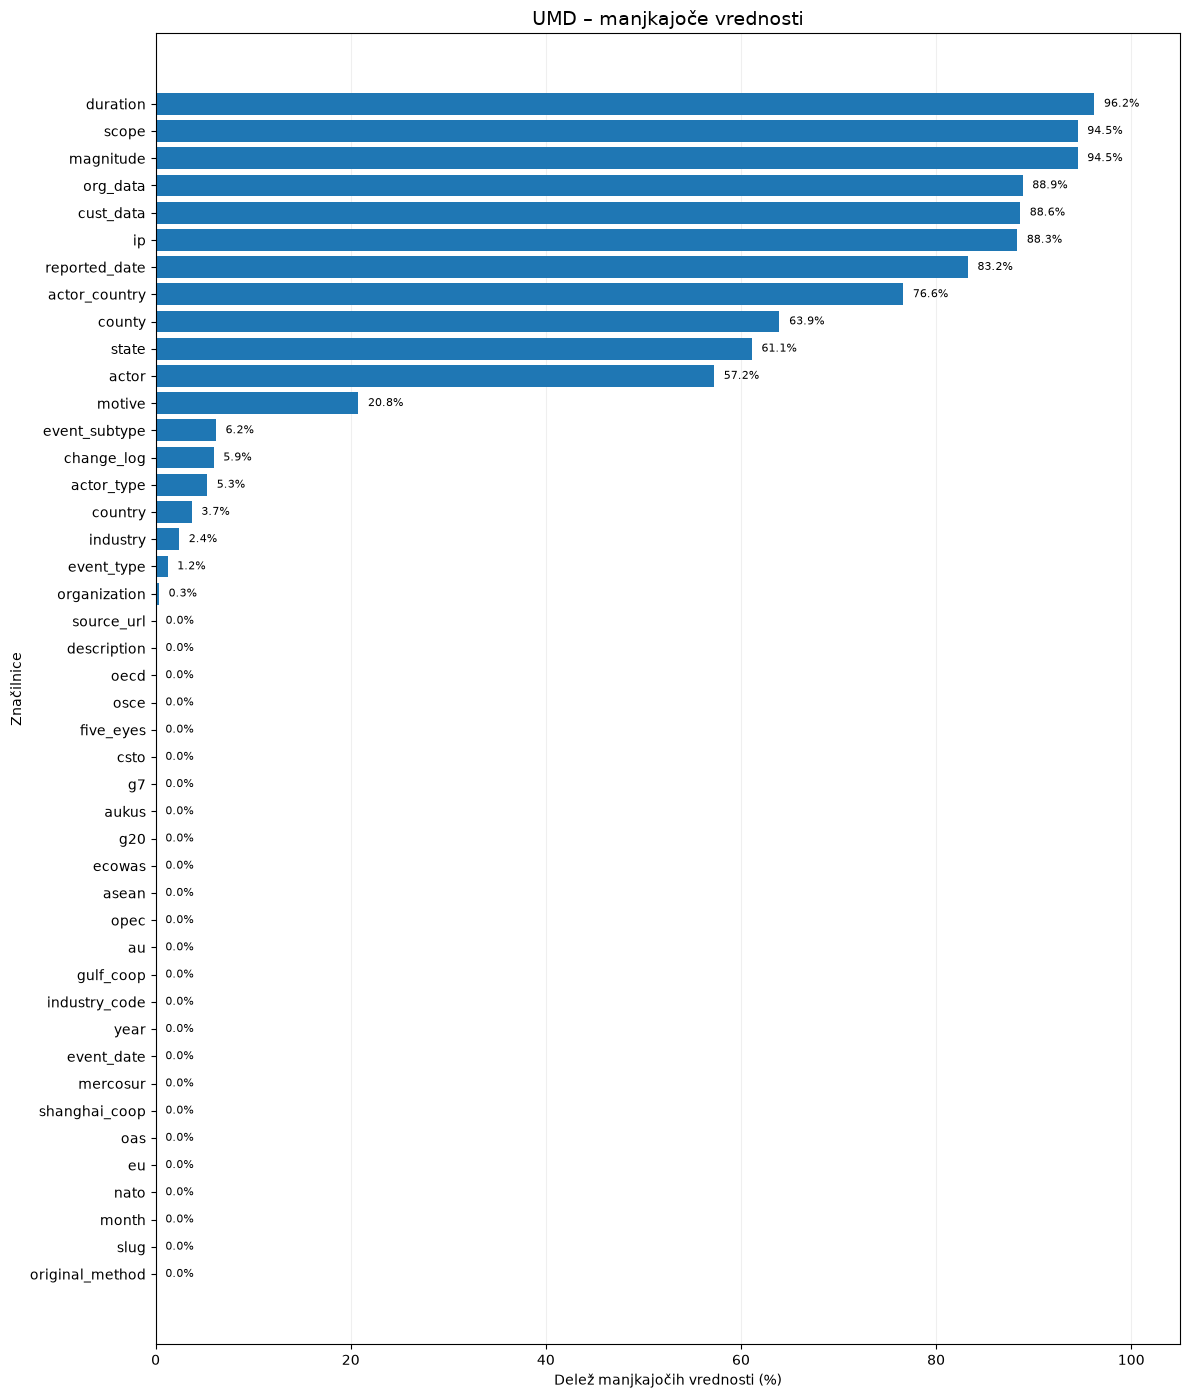

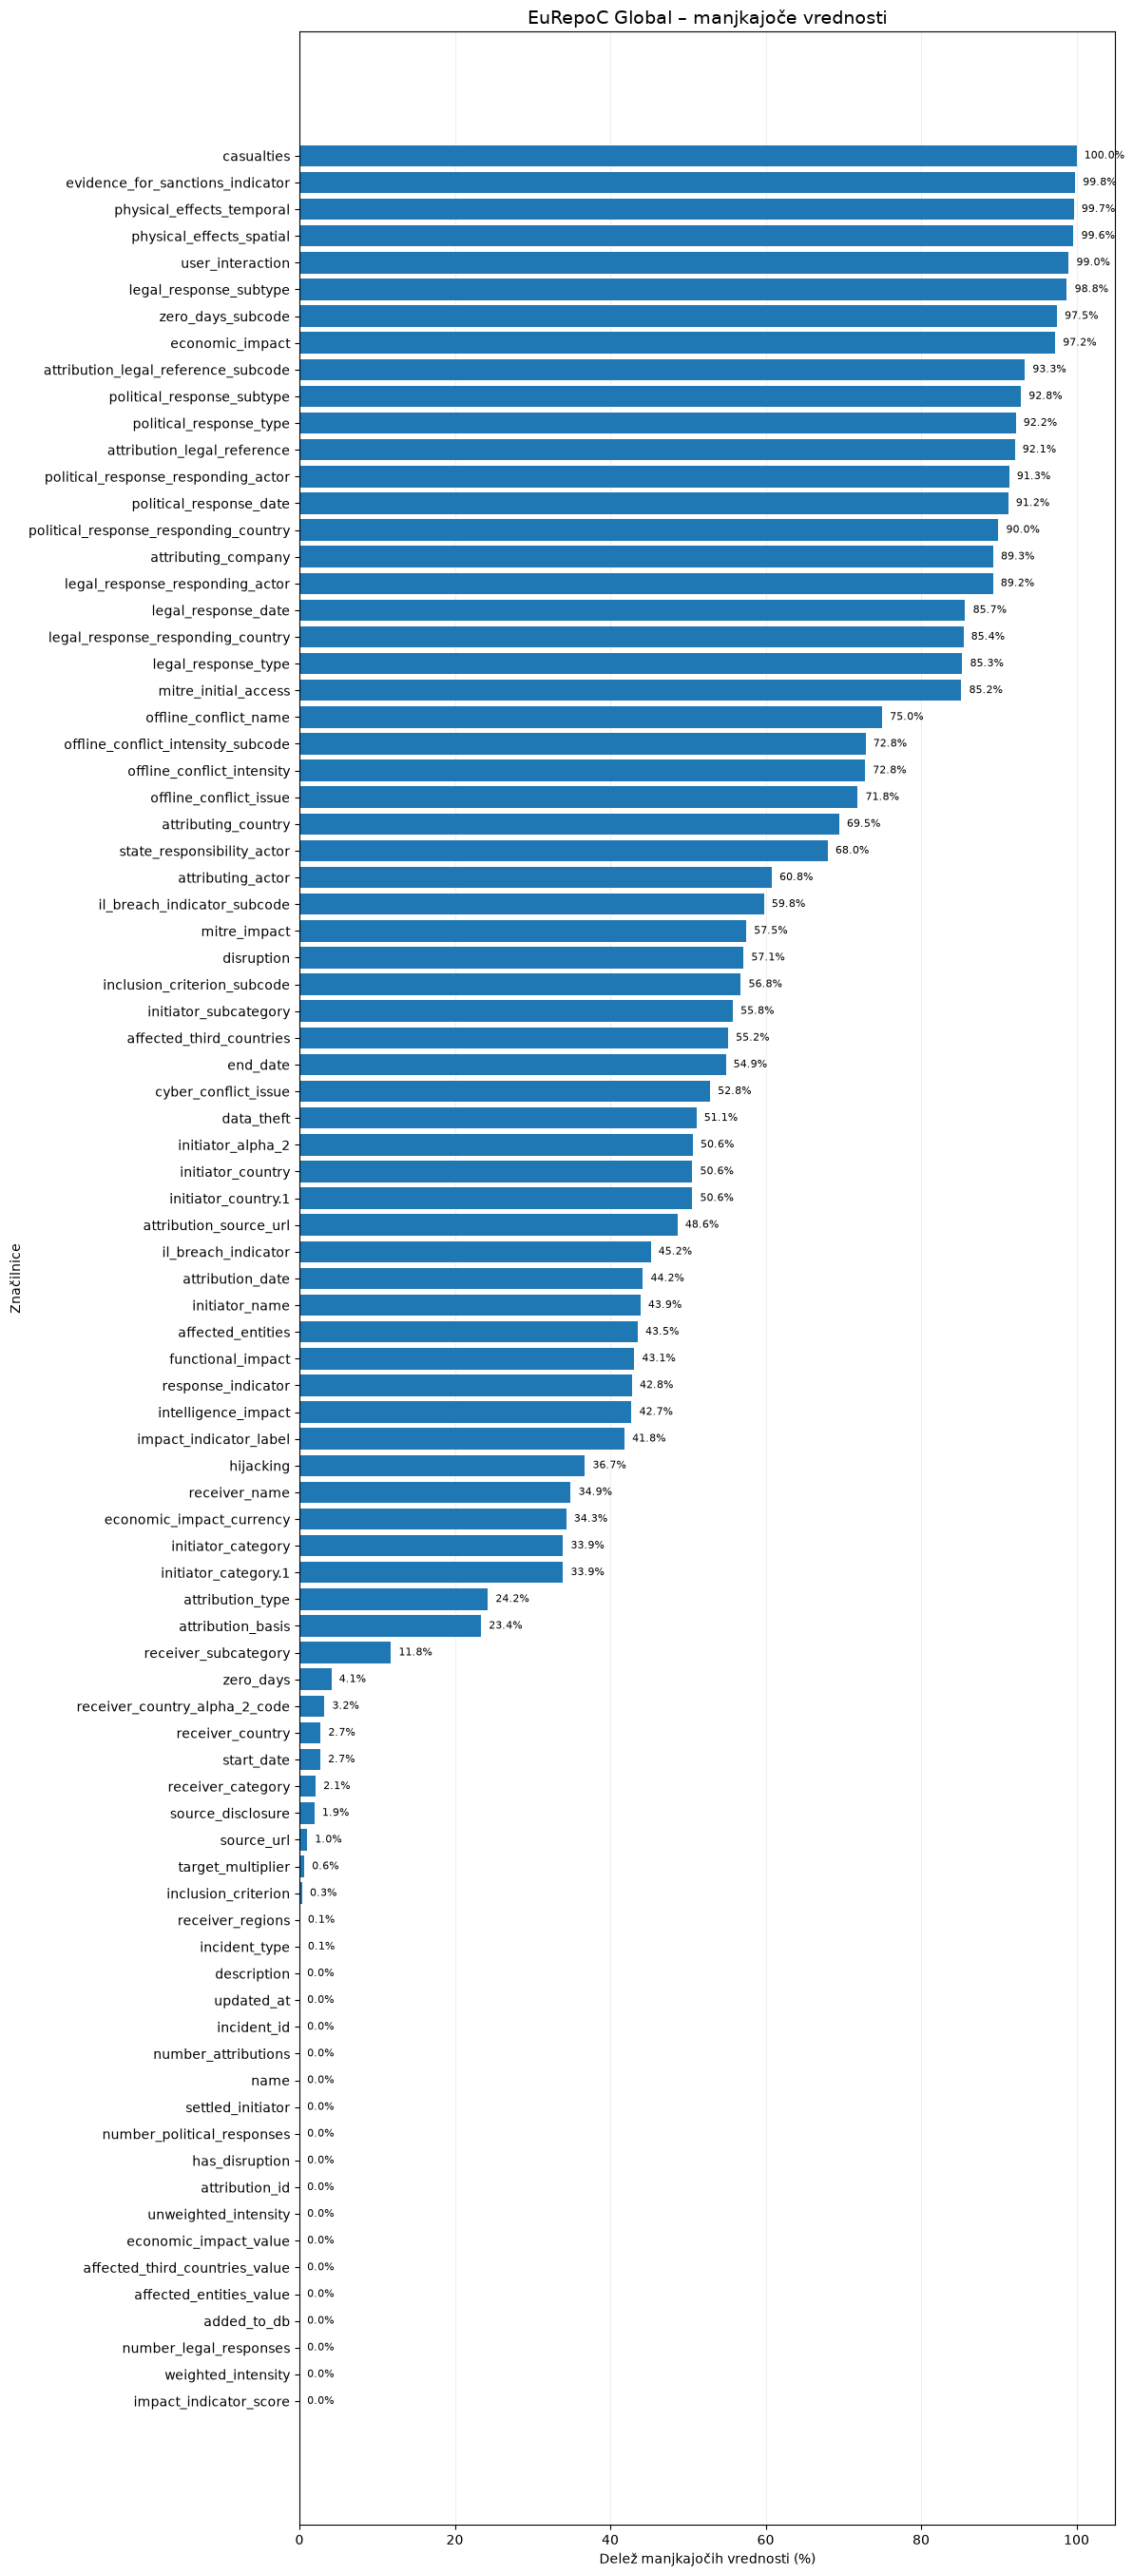

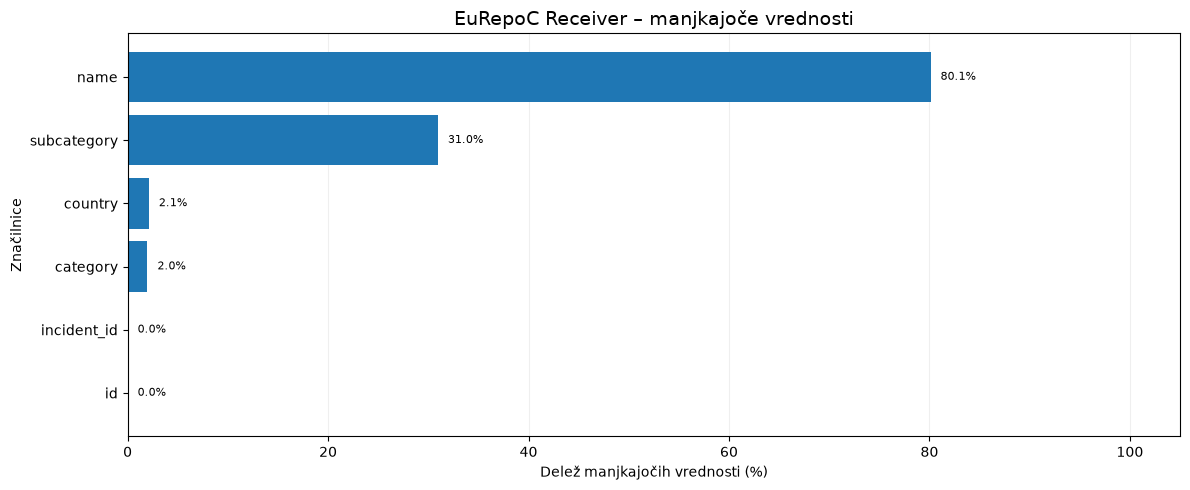

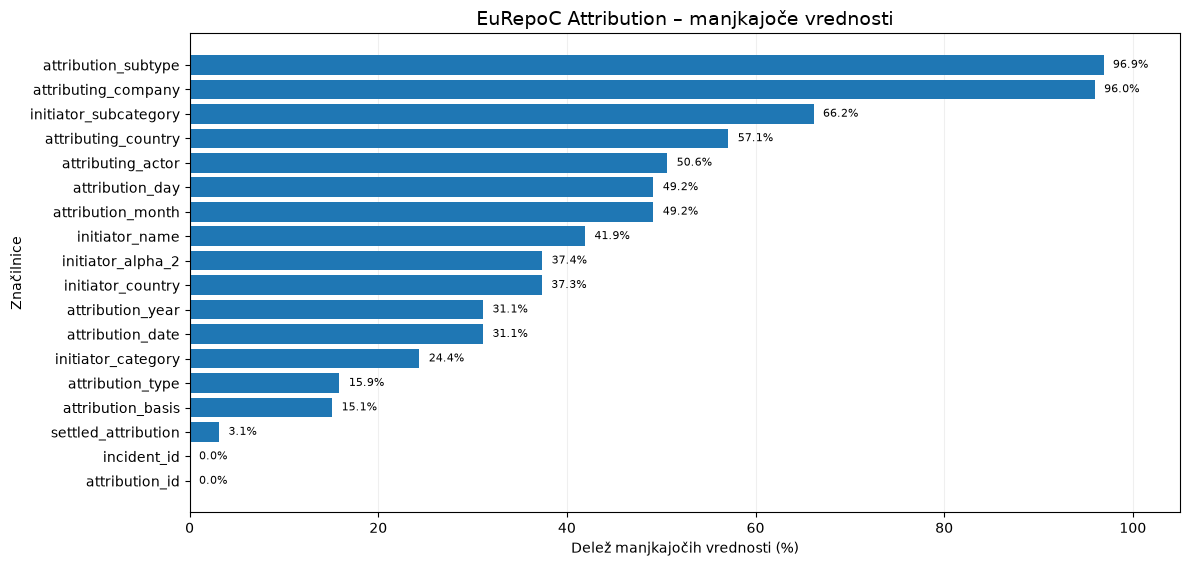

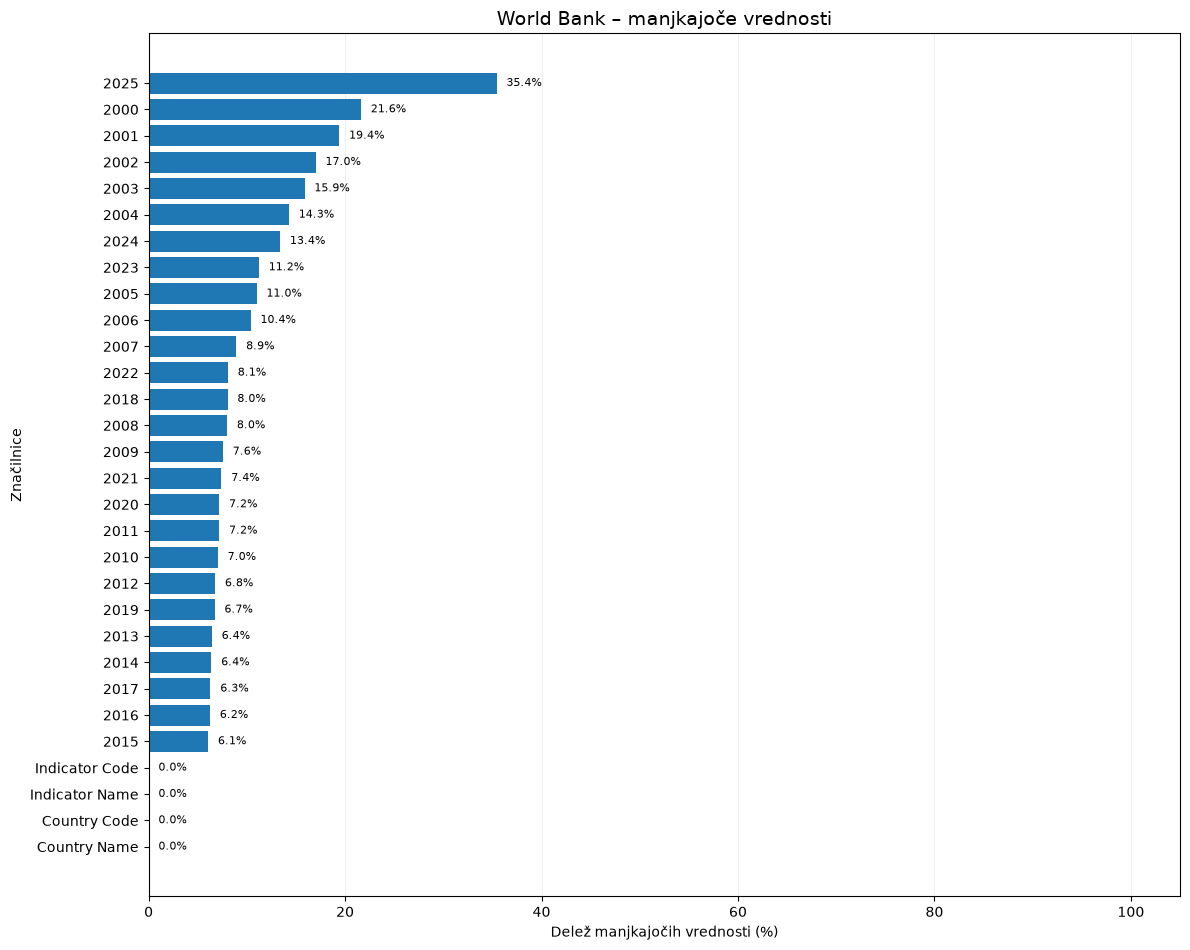

In [18]:
for name, result in missing_results.items():
    # Ureditev značilnic po deležu manjkajočih vrednosti
    plot_data = result.sort_values("Manjkajoče (%)", ascending=True)

    fig, ax = plt.subplots(
        figsize=(12, max(5, len(plot_data) * 0.32))
    )

    bars = ax.barh(
        plot_data["Značilnica"],
        plot_data["Manjkajoče (%)"]
    )

    ax.set_title(f"{name} – manjkajoče vrednosti", fontsize=14)
    ax.set_xlabel("Delež manjkajočih vrednosti (%)")
    ax.set_ylabel("Značilnice")
    ax.set_xlim(0, 105)

    # Prikaz odstotkov ob stolpcih
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va="center",
            fontsize=8
        )

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

### 3.4. Podvojitve, kategorije in veljavnost zapisov

Preverimo enoličnost identifikatorjev, povezave med podatkovnimi zbirkami in večvrednostne kategorije.

Posebno pozornost namenimo razlikovanju med:
- posameznim kibernetskim incidentom,
- prizadeto organizacijo oziroma entiteto,
- atribucijo odgovornosti za incident.

Pri zbirkah EuRepoC lahko en incident vključuje več prizadetih entitet ali atribucij, zato ponovljeni identifikatorji incidentov niso nujno napake.

In [19]:
id_columns = {
    "UMD": "slug",
    "EuRepoC Global": "incident_id",
    "EuRepoC Receiver": "id",
    "EuRepoC Attribution": "attribution_id"
}

results = []

for name, id_col in id_columns.items():
    df = datasets[name]

    results.append({
        "Zbirka": name,
        "Identifikator": id_col,
        "Vrstice": len(df),
        "Unikatni ID": df[id_col].nunique(),
        "Manjkajoči ID": df[id_col].isna().sum(),
        "Ponovljeni ID": df[id_col].duplicated().sum()
    })

display(pd.DataFrame(results))

,Zbirka,Identifikator,Vrstice,Unikatni ID,Manjkajoči ID,Ponovljeni ID
0,UMD,slug,17480,17480,0,0
1,EuRepoC Global,incident_id,3414,3414,0,0
2,EuRepoC Receiver,id,12180,12180,0,0
3,EuRepoC Attribution,attribution_id,5217,3805,0,1412


In [20]:
global_ids = set(eurepoc_global["incident_id"].dropna())
receiver_ids = set(eurepoc_receiver["incident_id"].dropna())
attribution_ids = set(eurepoc_attribution["incident_id"].dropna())

povezave = pd.DataFrame([
    {
        "Zbirka": "EuRepoC Receiver",
        "Različnih incidentov": len(receiver_ids),
        "Povezanih z Global": len(receiver_ids & global_ids),
        "Brez povezave z Global": len(receiver_ids - global_ids),
        "Incidentov Global brez zapisa v zbirki": len(global_ids - receiver_ids)
    },
    {
        "Zbirka": "EuRepoC Attribution",
        "Različnih incidentov": len(attribution_ids),
        "Povezanih z Global": len(attribution_ids & global_ids),
        "Brez povezave z Global": len(attribution_ids - global_ids),
        "Incidentov Global brez zapisa v zbirki": len(global_ids - attribution_ids)
    }
])

display(povezave)

,Zbirka,Različnih incidentov,Povezanih z Global,Brez povezave z Global,Incidentov Global brez zapisa v zbirki
0,EuRepoC Receiver,3322,3322,0,92
1,EuRepoC Attribution,3322,3322,0,92


koliko žrtev in atribucij ima posamezen incident?

In [21]:
receiver_counts = (
    eurepoc_receiver.groupby("incident_id")
    .size()
    .rename("Število zapisov žrtev")
)

attribution_counts = (
    eurepoc_attribution.groupby("incident_id")
    .size()
    .rename("Število atribucijskih zapisov")
)

display(receiver_counts.describe().to_frame("Receiver"))
display(attribution_counts.describe().to_frame("Attribution"))

print("Incidenti z več kot enim zapisom žrtve:",
      (receiver_counts > 1).sum())

print("Incidenti z več kot enim atribucijskim zapisom:",
      (attribution_counts > 1).sum())

,Receiver
count,3322.000000
mean,3.666466
std,20.687582
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,1089.000000


,Attribution
count,3322.000000
mean,1.570439
std,5.984020
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,192.000000


Incidenti z več kot enim zapisom žrtve: 1333
Incidenti z več kot enim atribucijskim zapisom: 590


In [22]:
columns_to_check = {
    "EuRepoC Global": [
        "incident_type",
        "receiver_country",
        "receiver_category",
        "receiver_subcategory"
    ],
    "EuRepoC Receiver": [
        "category",
        "subcategory"
    ]
}

results = []

for name, columns in columns_to_check.items():
    df = datasets[name]

    for col in columns:
        values = df[col].dropna().astype(str)
        multi = values.str.contains(";", regex=False)

        results.append({
            "Zbirka": name,
            "Značilnica": col,
            "Zapisov z več vrednostmi": multi.sum(),
            "Delež vseh zapisov (%)": round(
                multi.sum() / len(df) * 100, 2
            )
        })

display(pd.DataFrame(results))

,Zbirka,Značilnica,Zapisov z več vrednostmi,Delež vseh zapisov (%)
0,EuRepoC Global,incident_type,1737,50.88
1,EuRepoC Global,receiver_country,1365,39.98
2,EuRepoC Global,receiver_category,1365,39.98
3,EuRepoC Global,receiver_subcategory,1365,39.98
4,EuRepoC Receiver,category,0,0.00
5,EuRepoC Receiver,subcategory,0,0.00


#### Vizualizacija povezljivosti in večkratnosti zapisov

Grafično preverimo:
- delež incidentov EuRepoC Global, ki imajo povezane zapise v zbirkah Receiver in Attribution,
- delež incidentov z več kot enim povezanim zapisom,
- porazdelitev števila prizadetih entitet in atribucijskih zapisov na incident.

Pri tem upoštevamo, da je enota analize v Global posamezen incident, v Receiver prizadeta entiteta, v Attribution pa atribucijski zapis.

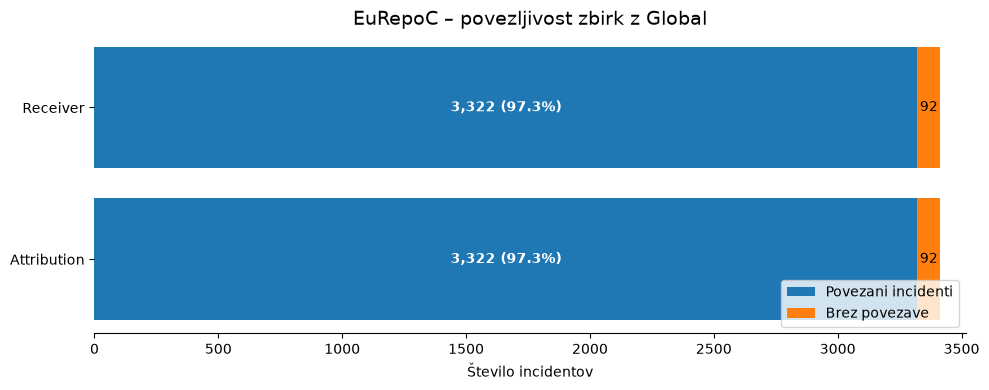

In [23]:
total = eurepoc_global["incident_id"].nunique()

linked = [
    len(global_ids & receiver_ids),
    len(global_ids & attribution_ids)
]

not_linked = [
    total - linked[0],
    total - linked[1]
]

labels = ["Receiver", "Attribution"]

fig, ax = plt.subplots(figsize=(10, 4))

y = np.arange(len(labels))

ax.barh(y, linked, label="Povezani incidenti")
ax.barh(y, not_linked, left=linked, label="Brez povezave")

for i, (a, b) in enumerate(zip(linked, not_linked)):
    ax.text(a / 2, i, f"{a:,} ({a/total:.1%})",
            ha="center", va="center", color="white", fontweight="bold")
    ax.text(a + b / 2, i, str(b),
            ha="center", va="center", fontsize=10)

ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, total * 1.03)
ax.set_xlabel("Število incidentov")
ax.set_title("EuRepoC – povezljivost zbirk z Global", fontsize=14)
ax.legend(loc="lower right")
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.show()

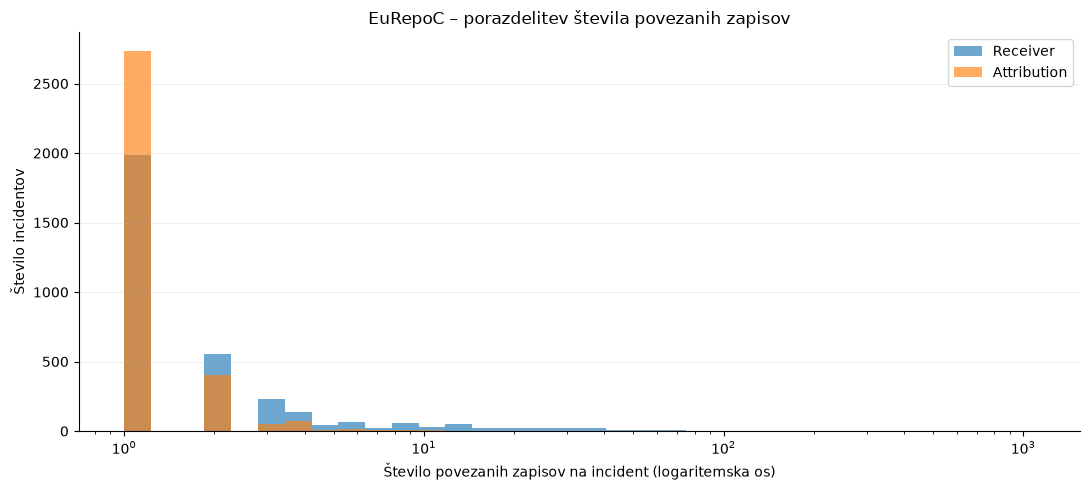

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))

bins = np.logspace(
    0,
    np.log10(max(receiver_counts.max(), attribution_counts.max()) + 1),
    35
)

ax.hist(
    receiver_counts,
    bins=bins,
    alpha=0.65,
    label="Receiver"
)

ax.hist(
    attribution_counts,
    bins=bins,
    alpha=0.65,
    label="Attribution"
)

ax.set_xscale("log")
ax.set_xlabel("Število povezanih zapisov na incident (logaritemska os)")
ax.set_ylabel("Število incidentov")
ax.set_title("EuRepoC – porazdelitev števila povezanih zapisov")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

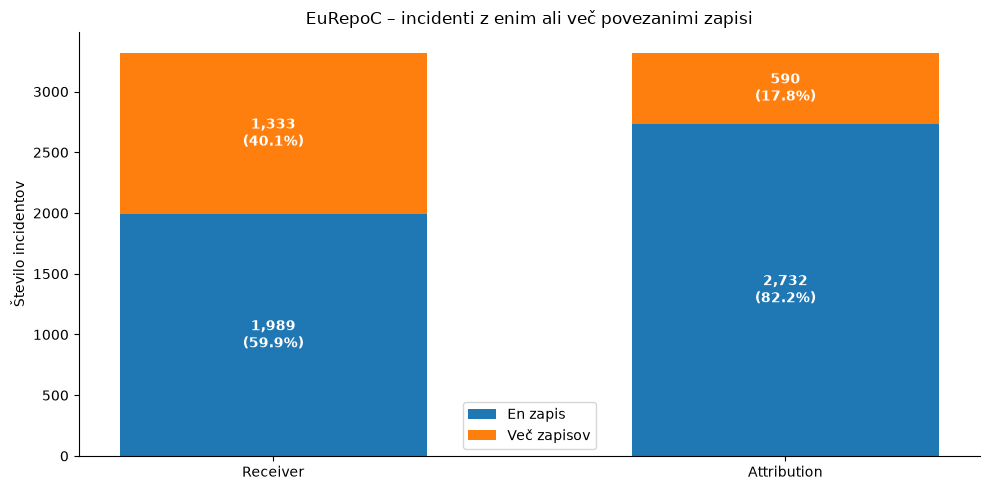

In [25]:
single_receiver = (receiver_counts == 1).sum()
multiple_receiver = (receiver_counts > 1).sum()

single_attribution = (attribution_counts == 1).sum()
multiple_attribution = (attribution_counts > 1).sum()

labels = ["Receiver", "Attribution"]
single = np.array([single_receiver, single_attribution])
multiple = np.array([multiple_receiver, multiple_attribution])

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(2)
width = 0.6

ax.bar(x, single, width, label="En zapis")
ax.bar(x, multiple, width, bottom=single, label="Več zapisov")

for i in range(2):
    total_records = single[i] + multiple[i]

    ax.text(
        i, single[i] / 2,
        f"{single[i]:,}\n({single[i]/total_records:.1%})",
        ha="center", va="center", color="white", fontweight="bold"
    )

    ax.text(
        i, single[i] + multiple[i] / 2,
        f"{multiple[i]:,}\n({multiple[i]/total_records:.1%})",
        ha="center", va="center", color="white", fontweight="bold"
    )

ax.set_xticks(x, labels)
ax.set_ylabel("Število incidentov")
ax.set_title("EuRepoC – incidenti z enim ali več povezanimi zapisi")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [26]:
# Kandidati za ponovljene dogodke v UMD:
# ista organizacija in isti datum

candidates = (
    umd.groupby(
        ["event_date", "organization"],
        dropna=False
    )
    .agg(
        st_zapisov=("slug", "size"),
        razlicnih_vrst=("event_subtype", "nunique"),
        razlicnih_opisov=("description", "nunique")
    )
    .reset_index()
    .query("st_zapisov > 1")
    .sort_values("st_zapisov", ascending=False)
)

print("Skupin z več kot enim zapisom:", len(candidates))
print("Skupno zapisov v teh skupinah:", candidates["st_zapisov"].sum())

display(candidates.head(20))

Skupin z več kot enim zapisom: 203
Skupno zapisov v teh skupinah: 460


,event_date,organization,st_zapisov,razlicnih_vrst,razlicnih_opisov
4525,2019-04-25,Cartoon Network,14,1,1
7328,2021-03-02,Union Power Ministry (10 Substations and Trans...,10,1,1
8547,2022-02-23,Undetermined,10,2,3
13131,2023-11-30,High-profile individuals working on Middle Eas...,6,1,1
7112,2021-02-01,"High-profile victims in the defense, aviation,...",6,1,1
10101,2022-09-30,Multiple governments in South America includin...,5,1,1
9444,2022-07-18,Belgium defense and interior ministries,4,1,4
8586,2022-02-28,Undetermined,4,2,2
8674,2022-03-15,Undetermined,4,2,2
12974,2023-11-13,Embassies and international organizations,4,1,1


In [27]:
umd.groupby(
        ["event_date", "organization"],
        dropna=False).agg(
        st_zapisov=("slug", "size"),
        razlicnih_vrst=("event_subtype", "nunique"),
        razlicnih_opisov=("description", "nunique")
    ).reset_index().query("st_zapisov > 1").sort_values("st_zapisov", ascending=False)


,event_date,organization,st_zapisov,razlicnih_vrst,razlicnih_opisov
4525,2019-04-25,Cartoon Network,14,1,1
7328,2021-03-02,Union Power Ministry (10 Substations and Trans...,10,1,1
8547,2022-02-23,Undetermined,10,2,3
13131,2023-11-30,High-profile individuals working on Middle Eas...,6,1,1
7112,2021-02-01,"High-profile victims in the defense, aviation,...",6,1,1
...,...,...,...,...,...
17106,2026-07-26,AnMed,2,2,2
17153,2026-07-31,Updoc,2,2,2
17170,2026-08-07,State of Berlin,2,2,2
17182,2026-08-13,"Carhartt, Inc.",2,1,2


In [28]:
umd [umd['organization'] == 'Cartoon Network']

,slug,original_method,event_date,reported_date,year,month,actor,actor_type,organization,industry_code,...,opec,gulf_coop,g7,g20,aukus,csto,oecd,osce,five_eyes,change_log
12933,1a3c170abba46e19,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,1,1,1,0,1,1,1,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12934,83b6497d2fcce971,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12935,3994867b1f09077b,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,0,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12936,143b1b68af769e1f,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,1,1,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12937,ea51e03e69127b16,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,1,0,1,0,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12938,9dd5e9ec9933d383,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12939,3756f7f665f1c2b8,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12940,972dbc6821a2fe52,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12941,a459de0fa1f0f5b3,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...
12942,a46e4db472e1c68e,1,2019-04-25,NaN,2019,4,Two Unnamed Brazilian Hackers,Hobbyist,Cartoon Network,71,...,0,0,0,0,0,0,1,1,0,[2026-03-02 15:45:26] Pipeline run: parsed MM/...


### 3.5. Geografska, časovna in vsebinska pokritost podatkov

Preverimo razpoložljivost podatkov po državah in letih ter ocenimo možnosti njihovega povezovanja.

Osredotočimo se na:
- geografsko pokritost dokumentiranih incidentov,
- razpoložljivost vrst incidentov in ciljnih sektorjev,
- časovno pokritost za obdobje 2014–2024,
- razpoložljivost gospodarskih in digitalnih kazalnikov World Bank,
- presek med podatkovnimi zbirkami,
- izvedljivost analiz pred pandemijo, med njo in po njej.

Nič incidentov v posamezni zbirki pomeni, da v njej ni evidentiranih incidentov za določeno državo in leto, ne da se incidenti niso zgodili.

In [30]:
import zipfile
# Obdobje raziskave
YEAR_START = 2014
YEAR_END = 2024
YEARS = list(range(YEAR_START, YEAR_END + 1))

# World Bank: metapodatki o državah
with zipfile.ZipFile(DATA_DIR / FILES["world_bank"]) as z:
    metadata_file = next(
        name for name in z.namelist()
        if name.startswith("Metadata_Country")
    )
    wb_metadata = pd.read_csv(z.open(metadata_file))

In [31]:
# Izločitev agregatov
wb_countries = wb_metadata.dropna(subset=["Region"]).copy()
valid_iso3 = set(wb_countries["Country Code"])

wb = world_bank[
    world_bank["Country Code"].isin(valid_iso3)
].copy()

# Pretvorba World Bank v dolgo obliko
wb_long = wb.melt(
    id_vars=[
        "Country Name", "Country Code",
        "Indicator Name", "Indicator Code"
    ],
    value_vars=[str(y) for y in YEARS],
    var_name="year",
    value_name="value"
)

wb_long["year"] = wb_long["year"].astype(int)
wb_long["value"] = pd.to_numeric(
    wb_long["value"], errors="coerce"
)

In [32]:
# Preslikava imen držav v ISO-3
def normalize_name(value):
    if pd.isna(value):
        return ""
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(c for c in value if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]", "", value.lower())

country_lookup = {
    normalize_name(row["TableName"]): row["Country Code"]
    for _, row in wb_countries.iterrows()
}

In [33]:
aliases = {
    "unitedstatesofamerica": "USA",
    "unitedstates": "USA",
    "unitedkingdomofgreatbritainandnorthernireland": "GBR",
    "unitedkingdom": "GBR",
    "russia": "RUS",
    "russianfederation": "RUS",
    "korearepublicof": "KOR",
    "southkorea": "KOR",
    "koreadempeoplesrepublicof": "PRK",
    "northkorea": "PRK",
    "iranislamicrepublicof": "IRN",
    "iran": "IRN",
    "turkey": "TUR",
    "turkiye": "TUR",
    "vietnam": "VNM",
    "viet nam": "VNM",
    "egypt": "EGY",
    "venezuela": "VEN",
    "slovakia": "SVK",
    "czechrepublic": "CZE",
    "syria": "SYR",
    "taiwan": "TWN"
}


In [34]:
country_lookup.update({
    normalize_name(k): v for k, v in aliases.items()
})

In [35]:
def to_iso3(name):
    return country_lookup.get(normalize_name(name), pd.NA)

In [36]:
# UMD
umd_cov = umd.copy()
umd_cov["iso3"] = umd_cov["country"].map(to_iso3)
umd_cov["year"] = pd.to_numeric(
    umd_cov["year"], errors="coerce"
)

umd_cov = umd_cov[
    umd_cov["year"].between(YEAR_START, YEAR_END)
].copy()

In [37]:
# EuRepoC: Global + Receiver
eurepoc_dates = eurepoc_global[[
    "incident_id", "start_date", "incident_type"
]].copy()

eurepoc_dates["year"] = pd.to_datetime(
    eurepoc_dates["start_date"],
    format="%d.%m.%Y",
    errors="coerce"
).dt.year

eurepoc_cov = eurepoc_receiver.merge(
    eurepoc_dates,
    on="incident_id",
    how="left",
    validate="many_to_one"
)

eurepoc_cov["iso3"] = eurepoc_cov["country"].map(to_iso3)

eurepoc_cov = eurepoc_cov[
    eurepoc_cov["year"].between(YEAR_START, YEAR_END)
].copy()

print("UMD – zapisi v obdobju:", len(umd_cov))
print("EuRepoC – zapisi Receiver v obdobju:", len(eurepoc_cov))
print("World Bank – države:", wb["Country Code"].nunique())

UMD – zapisi v obdobju: 14792
EuRepoC – zapisi Receiver v obdobju: 9876
World Bank – države: 217


In [38]:
# Preverjanje še neprepoznanih držav
for name, df in [
    ("UMD", umd_cov),
    ("EuRepoC", eurepoc_cov)
]:
    print(f"\n{name} – države brez ISO-3 preslikave:")
    display(
        df.loc[df["iso3"].isna(), "country"]
        .value_counts()
        .head(20)
        .to_frame("Zapisi")
    )


UMD – države brez ISO-3 preslikave:


,Zapisi
country,
Undetermined,436
Korea (the Republic of),90
Moldova (the Republic of),20
Venezuela (Bolivarian Republic of),20
Hong Kong,15
"Palestine, State of",7
European Union,3
Korea (the Democratic People's Republic of),3
"Tanzania, United Republic of",2



EuRepoC – države brez ISO-3 preslikave:


,Zapisi
country,
Not available,209
Europe (region),116
Global (region),92
Hong Kong,87
Middle East (region),82
Palestine,56
Asia (region),42
Southeast Asia (region),37
Unknown,35


In [39]:
# Dopolnitve imen držav, ki se med viri razlikujejo

additional_aliases = {
    "Korea (the Republic of)": "KOR",
    "Korea (the Democratic People's Republic of)": "PRK",
    "Korea, Democratic People's Republic of": "PRK",
    "Moldova (the Republic of)": "MDA",
    "Moldova, Republic of": "MDA",
    "Venezuela (Bolivarian Republic of)": "VEN",
    "Palestine, State of": "PSE",
    "Palestine": "PSE",
    "Hong Kong": "HKG",
    "Macao": "MAC",
    "Macau": "MAC",
    "Tanzania, United Republic of": "TZA",
    "Bolivia (Plurinational State of)": "BOL",
    "Bahamas": "BHS",
    "Lao People's Democratic Republic": "LAO",
    "Laos": "LAO",
    "Kyrgyzstan": "KGZ",
    "Brunei": "BRN",
    "Yemen": "YEM",
    "Saint Vincent and the Grenadines": "VCT",
    "Puerto Rico": "PRI",
    "Nauru": "NRU",
    "Guadeloupe": "GLP",
    "Bonaire, Sint Eustatius and Saba": "BES",
    "Holy See": "VAT"
}

In [40]:
country_lookup.update({
    normalize_name(name): code
    for name, code in additional_aliases.items()
})

In [41]:
# Ponovna preslikava
umd_cov["iso3"] = umd_cov["country"].map(to_iso3)
eurepoc_cov["iso3"] = eurepoc_cov["country"].map(to_iso3)

In [42]:
# Preverimo, kaj še vedno ni prepoznano
for name, df in [
    ("UMD", umd_cov),
    ("EuRepoC", eurepoc_cov)
]:
    missing = df[df["iso3"].isna()]

    print(f"\n{name}")
    print("Neprepoznani zapisi:", len(missing))
    print("Delež:", round(len(missing) / len(df) * 100, 2), "%")

    display(
        missing["country"]
        .value_counts()
        .head(20)
        .to_frame("Število")
    )


UMD
Neprepoznani zapisi: 443
Delež: 2.99 %


,Število
country,
Undetermined,436
European Union,3
Saint Thomas,1
French Guiana,1
Republic of North Macedonia,1
Sint Maarten,1



EuRepoC
Neprepoznani zapisi: 848
Delež: 8.59 %


,Število
country,
Not available,209
Europe (region),116
Global (region),92
Middle East (region),82
Asia (region),42
Southeast Asia (region),37
Unknown,35
Eastern Europe,29
Africa,23


In [43]:
# Veljavnost ključnih kategorij
missing_labels = {
    "", "unknown", "undetermined",
    "not available", "not attributed",
    "n/a", "na"
}

In [44]:
def is_known(series):
    s = series.astype("string").str.strip().str.lower()
    return series.notna() & ~s.isin(missing_labels)

In [45]:
# 1. UMD – število incidentov
umd_counts = (
    umd_cov.dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["slug"]
    .nunique()
    .rename("umd_incidents")
)

umd_type = (
    umd_cov[
        is_known(umd_cov["event_subtype"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["slug"]
    .nunique()
    .rename("umd_known_type")
)

umd_sector = (
    umd_cov[
        is_known(umd_cov["industry"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["slug"]
    .nunique()
    .rename("umd_known_sector")
)

In [46]:
# 2. EuRepoC – število unikatnih incidentov
eur_counts = (
    eurepoc_cov.dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["incident_id"]
    .nunique()
    .rename("eur_incidents")
)

eur_type = (
    eurepoc_cov[
        is_known(eurepoc_cov["incident_type"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["incident_id"]
    .nunique()
    .rename("eur_known_type")
)

eur_sector = (
    eurepoc_cov[
        is_known(eurepoc_cov["category"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["incident_id"]
    .nunique()
    .rename("eur_known_sector")
)

In [47]:
# 3. World Bank – število dostopnih kazalnikov
wb_available = (
    wb_long[wb_long["value"].notna()]
    .groupby(["Country Code", "year"])["Indicator Code"]
    .nunique()
    .rename("wb_available")
)

wb_available.index = wb_available.index.set_names(
    ["iso3", "year"]
)

In [48]:
# 4. Skupna matrika
all_iso3 = sorted(
    valid_iso3
    | set(umd_cov["iso3"].dropna())
    | set(eurepoc_cov["iso3"].dropna())
)

index = pd.MultiIndex.from_product(
    [all_iso3, YEARS],
    names=["iso3", "year"]
)

coverage = pd.DataFrame(index=index)

for s in [
    umd_counts, umd_type, umd_sector,
    eur_counts, eur_type, eur_sector,
    wb_available
]:
    coverage = coverage.join(s)

coverage = coverage.fillna(0).astype(int).reset_index()

country_names = (
    wb_countries
    .set_index("Country Code")["TableName"]
    .to_dict()
)

In [49]:
# Tudi države, ki niso v World Bank
for name, code in additional_aliases.items():
    country_names.setdefault(code, name)

coverage.insert(
    1, "country",
    coverage["iso3"].map(country_names).fillna(coverage["iso3"])
)

coverage["has_umd"] = coverage["umd_incidents"] > 0
coverage["has_eur"] = coverage["eur_incidents"] > 0
coverage["wb_complete"] = coverage["wb_available"] == 8

print("Velikost matrike:", coverage.shape)
display(coverage.head(10))

Velikost matrike: (2431, 13)


,iso3,country,year,umd_incidents,umd_known_type,umd_known_sector,eur_incidents,eur_known_type,eur_known_sector,wb_available,has_umd,has_eur,wb_complete
0,ABW,Aruba,2014,0,0,0,0,0,0,8,False,False,True
1,ABW,Aruba,2015,0,0,0,0,0,0,8,False,False,True
2,ABW,Aruba,2016,0,0,0,0,0,0,7,False,False,False
3,ABW,Aruba,2017,0,0,0,0,0,0,7,False,False,False
4,ABW,Aruba,2018,0,0,0,0,0,0,6,False,False,False
5,ABW,Aruba,2019,0,0,0,0,0,0,7,False,False,False
6,ABW,Aruba,2020,0,0,0,0,0,0,7,False,False,False
7,ABW,Aruba,2021,0,0,0,0,0,0,7,False,False,False
8,ABW,Aruba,2022,0,0,0,0,0,0,7,False,False,False
9,ABW,Aruba,2023,0,0,0,0,0,0,6,False,False,False


In [50]:
country_summary = (
    coverage.groupby(["iso3", "country"])
    .agg(
        umd_incidents=("umd_incidents", "sum"),
        eur_incidents=("eur_incidents", "sum"),
        umd_years=("has_umd", "sum"),
        eur_years=("has_eur", "sum"),
        umd_known_type=("umd_known_type", "sum"),
        umd_known_sector=("umd_known_sector", "sum"),
        eur_known_type=("eur_known_type", "sum"),
        eur_known_sector=("eur_known_sector", "sum"),
        wb_complete_years=("wb_complete", "sum")
    )
    .reset_index()
)

country_summary["both_sources"] = (
    (country_summary["umd_incidents"] > 0)
    & (country_summary["eur_incidents"] > 0)
)

In [51]:
print("Države z incidenti UMD:",
      (country_summary["umd_incidents"] > 0).sum())

print("Države z incidenti EuRepoC:",
      (country_summary["eur_incidents"] > 0).sum())

print("Države z incidenti v obeh virih:",
      country_summary["both_sources"].sum())

print("Države z vsemi 8 WDI kazalniki v vsaj enem letu:",
      (country_summary["wb_complete_years"] > 0).sum())

print("Države z vsemi 8 WDI kazalniki v vseh 11 letih:",
      (country_summary["wb_complete_years"] == 11).sum())

display(
    country_summary.sort_values(
        "umd_incidents", ascending=False
    ).head(30)
)

Države z incidenti UMD: 161
Države z incidenti EuRepoC: 155
Države z incidenti v obeh virih: 139
Države z vsemi 8 WDI kazalniki v vsaj enem letu: 187
Države z vsemi 8 WDI kazalniki v vseh 11 letih: 123


,iso3,country,umd_incidents,eur_incidents,umd_years,eur_years,umd_known_type,umd_known_sector,eur_known_type,eur_known_sector,wb_complete_years,both_sources
206,USA,United States,7200,705,11,11,6755,7141,705,697,8,True
69,GBR,United Kingdom,792,128,11,11,749,790,128,125,11,True
97,ITA,Italy,419,74,11,10,399,405,74,70,11,True
167,RUS,Russian Federation,417,193,11,11,385,413,193,189,11,True
204,UKR,Ukraine,416,127,11,11,390,405,127,115,11,True
33,CAN,Canada,378,72,11,11,358,370,72,68,9,True
91,IND,India,332,90,11,11,317,325,90,87,11,True
65,FRA,France,281,117,11,11,268,268,117,113,11,True
10,AUS,Australia,268,53,11,10,250,266,53,50,11,True
51,DEU,Germany,259,148,11,11,243,250,147,145,11,True


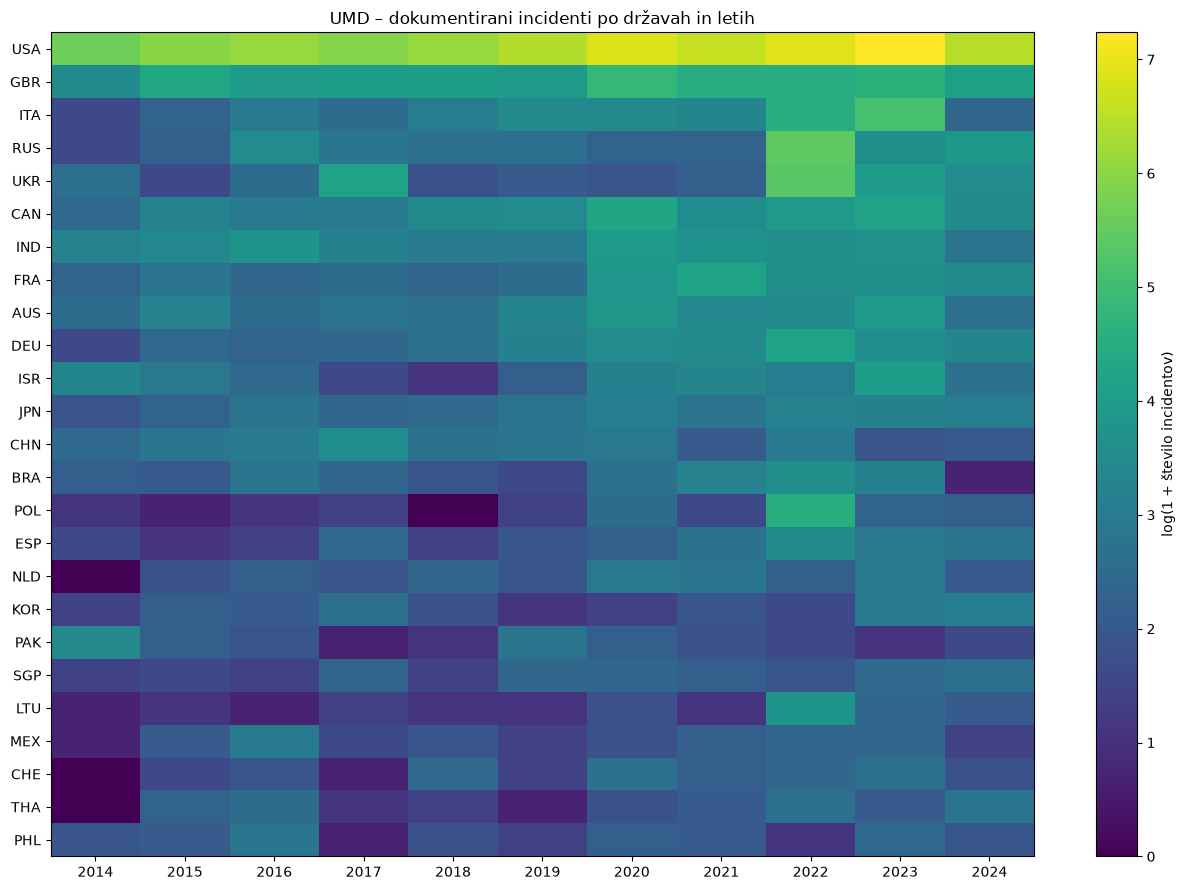

In [52]:
top_25 = (
    country_summary.nlargest(25, "umd_incidents")["iso3"]
    .tolist()
)

matrix = (
    coverage[coverage["iso3"].isin(top_25)]
    .pivot(index="iso3", columns="year", values="umd_incidents")
    .reindex(top_25)
)

fig, ax = plt.subplots(figsize=(13, 9))

im = ax.imshow(
    np.log1p(matrix.values),
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix.index)), matrix.index)

ax.set_title(
    "UMD – dokumentirani incidenti po državah in letih"
)

fig.colorbar(
    im, ax=ax,
    label="log(1 + število incidentov)"
)

plt.tight_layout()
plt.show()

In [53]:
# Začetni pragovi za raziskovalno izvedljivost.
# Niso formalni statistični kriteriji.

MIN_INCIDENTS = 30
MIN_YEARS = 5

In [54]:
# Osnovni World Bank kazalniki
basic_indicators = [
    "NY.GDP.PCAP.PP.KD",  # BDP na prebivalca
    "NV.IND.TOTL.ZS",    # industrija
    "NV.SRV.TOTL.ZS",    # storitve
    "IT.NET.USER.ZS"     # uporaba interneta
]


In [55]:
# Koliko osnovnih kazalnikov je na voljo za vsako državo/leto?
wb_basic = (
    wb_long[
        wb_long["Indicator Code"].isin(basic_indicators)
        & wb_long["value"].notna()
    ]
    .groupby(["Country Code", "year"])["Indicator Code"]
    .nunique()
    .rename("wb_basic_available")
    .reset_index()
    .rename(columns={"Country Code": "iso3"})
)

In [56]:
coverage2 = coverage.merge(
    wb_basic,
    on=["iso3", "year"],
    how="left",
    validate="one_to_one"
)

coverage2["wb_basic_available"] = (
    coverage2["wb_basic_available"].fillna(0).astype(int)
)

summary2 = (
    coverage2.groupby(["iso3", "country"])
    .agg(
        umd_incidents=("umd_incidents", "sum"),
        eur_incidents=("eur_incidents", "sum"),
        umd_years=("has_umd", "sum"),
        eur_years=("has_eur", "sum"),
        wb_basic_years=(
            "wb_basic_available",
            lambda x: (x == 4).sum()
        ),
        wb_all_years=(
            "wb_available",
            lambda x: (x == 8).sum()
        )
    )
    .reset_index()
)

In [57]:
summary2["umd_eda"] = (
    summary2["umd_incidents"] >= MIN_INCIDENTS
)

summary2["eur_eda"] = (
    summary2["eur_incidents"] >= MIN_INCIDENTS
)

summary2["umd_time"] = (
    (summary2["umd_incidents"] >= MIN_INCIDENTS)
    & (summary2["umd_years"] >= MIN_YEARS)
)

summary2["eur_time"] = (
    (summary2["eur_incidents"] >= MIN_INCIDENTS)
    & (summary2["eur_years"] >= MIN_YEARS)
)

summary2["umd_economy"] = (
    summary2["umd_eda"]
    & (summary2["wb_basic_years"] >= MIN_YEARS)
)

summary2["eur_economy"] = (
    summary2["eur_eda"]
    & (summary2["wb_basic_years"] >= MIN_YEARS)
)

In [58]:
feasibility = pd.DataFrame([
    {
        "Analiza": "UMD – profili incidentov",
        "Držav": summary2["umd_eda"].sum()
    },
    {
        "Analiza": "EuRepoC – profili incidentov",
        "Držav": summary2["eur_eda"].sum()
    },
    {
        "Analiza": "UMD – časovne primerjave",
        "Držav": summary2["umd_time"].sum()
    },
    {
        "Analiza": "EuRepoC – časovne primerjave",
        "Držav": summary2["eur_time"].sum()
    },
    {
        "Analiza": "UMD + gospodarstvo",
        "Držav": summary2["umd_economy"].sum()
    },
    {
        "Analiza": "EuRepoC + gospodarstvo",
        "Držav": summary2["eur_economy"].sum()
    }
])

In [59]:
display(feasibility)

,Analiza,Držav
0,UMD – profili incidentov,48
1,EuRepoC – profili incidentov,30
2,UMD – časovne primerjave,47
3,EuRepoC – časovne primerjave,30
4,UMD + gospodarstvo,47
5,EuRepoC + gospodarstvo,29


In [60]:
# Katere države izpolnjujejo pogoje?
display(
    summary2[
        summary2["umd_economy"]
        | summary2["eur_economy"]
    ].sort_values("umd_incidents", ascending=False)
)

,iso3,country,umd_incidents,eur_incidents,umd_years,eur_years,wb_basic_years,wb_all_years,umd_eda,eur_eda,umd_time,eur_time,umd_economy,eur_economy
206,USA,United States,7200,705,11,11,8,8,True,True,True,True,True,True
69,GBR,United Kingdom,792,128,11,11,11,11,True,True,True,True,True,True
97,ITA,Italy,419,74,11,10,11,11,True,True,True,True,True,True
167,RUS,Russian Federation,417,193,11,11,11,11,True,True,True,True,True,True
204,UKR,Ukraine,416,127,11,11,11,11,True,True,True,True,True,True
33,CAN,Canada,378,72,11,11,9,9,True,True,True,True,True,True
91,IND,India,332,90,11,11,11,11,True,True,True,True,True,True
65,FRA,France,281,117,11,11,11,11,True,True,True,True,True,True
10,AUS,Australia,268,53,11,10,11,11,True,True,True,True,True,True
51,DEU,Germany,259,148,11,11,11,11,True,True,True,True,True,True


In [61]:
periods = {
    "Pred pandemijo": (2017, 2019),
    "Med pandemijo": (2020, 2021),
    "Po pandemiji": (2022, 2024)
}

period_data = []

for name, (start, end) in periods.items():
    temp = coverage2[
        coverage2["year"].between(start, end)
    ]

    for iso3, group in temp.groupby("iso3"):
        period_data.append({
            "iso3": iso3,
            "obdobje": name,
            "umd_incidents": group["umd_incidents"].sum(),
            "eur_incidents": group["eur_incidents"].sum(),
            "wb_basic_complete_years": (
                group["wb_basic_available"] == 4
            ).sum()
        })

period_df = pd.DataFrame(period_data)

In [62]:
# Države, ki imajo vsaj 10 dokumentiranih
# incidentov UMD v VSAKEM obdobju
umd_pivot = period_df.pivot(
    index="iso3",
    columns="obdobje",
    values="umd_incidents"
)

eur_pivot = period_df.pivot(
    index="iso3",
    columns="obdobje",
    values="eur_incidents"
)

umd_eligible = umd_pivot[
    (umd_pivot >= 10).all(axis=1)
]

eur_eligible = eur_pivot[
    (eur_pivot >= 10).all(axis=1)
]

print(
    "Države z vsaj 10 incidenti UMD v vseh treh obdobjih:",
    len(umd_eligible)
)

print(
    "Države z vsaj 10 incidenti EuRepoC v vseh treh obdobjih:",
    len(eur_eligible)
)

display(umd_eligible)
display(eur_eligible)

Države z vsaj 10 incidenti UMD v vseh treh obdobjih: 26
Države z vsaj 10 incidenti EuRepoC v vseh treh obdobjih: 7


obdobje,Med pandemijo,Po pandemiji,Pred pandemijo
iso3,,,
AUS,73,92,55
BRA,37,59,20
CAN,102,142,81
CHE,21,28,15
CHN,24,31,63
CZE,12,17,12
DEU,62,127,46
ESP,22,62,20
FRA,110,103,33


obdobje,Med pandemijo,Po pandemiji,Pred pandemijo
iso3,,,
GBR,11,68,20
IND,16,35,16
ISR,18,49,15
KOR,13,33,17
RUS,12,137,18
UKR,16,79,13
USA,54,482,78


#### 3.5.1. Vsebinska pokritost vrst incidentov in ciljnih sektorjev

Poleg števila dokumentiranih incidentov preverimo tudi raznolikost njihovih vrst in ciljnih sektorjev.

Analiziramo:
- zastopanost posameznih vrst incidentov,
- zastopanost ciljnih sektorjev,
- število različnih kategorij po državah,
- število incidentov v najpogostejših kategorijah.

Pri EuRepoC se lahko posamezen incident uvršča v več vrst incidentov oziroma prizadene več sektorjev. Zato za frekvence kategorij uporabljamo ustrezno razčlenitev in štejemo unikatne incidente.

In [63]:
# UMD: razčlenitev večvrednostnih podtipov
umd_subtypes = (
    umd_cov[["slug", "iso3", "year", "event_subtype"]]
    .dropna(subset=["event_subtype"])
    .assign(
        event_subtype=lambda df: (
            df["event_subtype"].str.split(",")
        )
    )
    .explode("event_subtype")
)

umd_subtypes["event_subtype"] = (
    umd_subtypes["event_subtype"]
    .str.strip()
    .str.replace(
        "Exploitation Of Application Server",
        "Exploitation of Application Server",
        regex=False
    )
)

umd_subtypes = (
    umd_subtypes[
        is_known(umd_subtypes["event_subtype"])
    ]
    .drop_duplicates(["slug", "event_subtype"])
)

subtype_counts = (
    umd_subtypes.groupby("event_subtype")["slug"]
    .nunique()
    .sort_values(ascending=False)
)

print("Osnovnih podtipov:", len(subtype_counts))
display(subtype_counts.to_frame("Incidenti"))

Osnovnih podtipov: 13


,Incidenti
event_subtype,
Exploitation of Application Server,6440
Data Attack,3734
External Denial of Service,1697
Exploitation of End Hosts,1677
Message Manipulation,1325
Exploitation of Sensors,186
Internal Denial of Service,136
Exploitation of Network Infrastructure,98
Physical Attack,80


In [64]:
# UMD – pregled glavnih vrst in sektorjev
for col in ["event_type", "event_subtype", "industry"]:
    print(f"\nUMD – {col}")

    counts = (
        umd_cov.loc[is_known(umd_cov[col]), col]
        .value_counts()
        .rename_axis("Kategorija")
        .reset_index(name="Incidenti")
    )

    print("Različnih kategorij:", len(counts))
    display(counts.head(20))


UMD – event_type
Različnih kategorij: 3


,Kategorija,Incidenti
0,Exploitive,7494
1,Disruptive,4494
2,Mixed,2611



UMD – event_subtype
Različnih kategorij: 73


,Kategorija,Incidenti
0,Exploitation of Application Server,5150
1,Data Attack,2772
2,External Denial of Service,1521
3,Exploitation of End Hosts,1283
4,Message Manipulation,1155
5,"Data Attack,Exploitation of Application Server",751
6,"Exploitation of Application Server,Exploitatio...",316
7,Exploitation of Sensors,172
8,"Message Manipulation,Exploitation of Applicati...",89
9,Exploitation of Network Infrastructure,81



UMD – industry
Različnih kategorij: 24


,Kategorija,Incidenti
0,Public Administration,2764
1,Health Care and Social Assistance,2029
2,Information,1503
3,Finance and Insurance,1430
4,Educational Services,1372
5,"Professional, Scientific, and Technical Services",1237
6,Other Services (except Public Administration),944
7,Manufacturing,684
8,Retail Trade,493
9,Transportation and Warehousing,465


In [65]:
# EuRepoC Global – večvrednostne vrste incidentov
eur_types = eurepoc_dates.copy()

eur_types["year"] = pd.to_numeric(
    eur_types["year"], errors="coerce"
)

eur_types = eur_types[
    eur_types["year"].between(YEAR_START, YEAR_END)
]

eur_types = eur_types.assign(
    incident_type=eur_types["incident_type"]
    .astype("string").str.split(";")
).explode("incident_type")

eur_types["incident_type"] = (
    eur_types["incident_type"].str.strip()
)

eur_types = eur_types[
    is_known(eur_types["incident_type"])
].drop_duplicates(["incident_id", "incident_type"])

print("\nEuRepoC – vrste incidentov")

display(
    eur_types.groupby("incident_type")["incident_id"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("Incidenti")
)


EuRepoC – vrste incidentov


,Incidenti
incident_type,
Hijacking with Misuse,1668
Disruption,1170
Data theft,1012
Ransomware,492
Hijacking without Misuse,326
Data theft & Doxing,322


In [66]:
# EuRepoC Receiver – kategorije ciljnih sektorjev
eur_sector_counts = (
    eurepoc_cov[
        is_known(eurepoc_cov["category"])
    ]
    .groupby("category")["incident_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nEuRepoC – kategorije prizadetih entitet")
display(eur_sector_counts.to_frame("Incidenti"))

print("\nEuRepoC – podkategorije")
display(
    eurepoc_cov[
        is_known(eurepoc_cov["subcategory"])
    ]
    .groupby(["category", "subcategory"])["incident_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(30)
    .to_frame("Incidenti")
)



EuRepoC – kategorije prizadetih entitet


,Incidenti
category,
State institutions / political system,1357
Critical infrastructure,1249
Corporate Targets (corporate targets only coded if the respective company is not part of the critical infrastructure definition),381
Education,185
Social groups,173
Media,166
End user(s) / specially protected groups,72
Science,67
International / supranational organization,53



EuRepoC – podkategorije


Incidenti
category                              subcategory                                                  
State institutions / political system Government / ministries                                   559
                                      Civil service / administration                            528
Critical infrastructure               Health                                                    274
                                      Finance                                                   248
                                      Telecommunications                                        190
                                      Transportation                                            177
                                      Energy                                                    153
State institutions / political system Military                                                  138
Critical infrastructure               Research                                                  103
                                      Defence industry                                          101
                                      Critical Manufacturing                                     98
State institutions / political system Police                                                     90
Social groups                         Advocacy / activists (e.g. human rights organiz...         74
Critical infrastructure               Digital Provider                                           60
State institutions / political system Legislative                                                57
                                      Political parties                                          54
                                      Judiciary                                                  46
                                      Other (e.g., embassies)                                    45
                                      Election infrastructure / related systems                  42
Critical infrastructure               Food                                                       38
State institutions / political system Intelligence agencies                                      37
Social groups                         Political opposition / dissidents / expats                 33
                                      Other social groups                                        31
Critical infrastructure               Water                                                      24
                                      Chemicals                                                  23
Social groups                         Religious                                                  18
Critical infrastructure               Space                                                      18
Social groups                         Ethnic                                                     14
                                      Criminal                                                   11
Critical infrastructure               Waste Water Management                                     10

Koliko imamo dejansko primerljivih zapisov država–leto?

In [67]:
# UMD – število različnih vrst in sektorjev na državo
umd_diversity = (
    umd_cov.dropna(subset=["iso3"])
    .groupby("iso3")
    .agg(
        incidents=("slug", "nunique"),
        types=("event_subtype",
               lambda x: x[is_known(x)].nunique()),
        sectors=("industry",
                 lambda x: x[is_known(x)].nunique())
    )
    .add_prefix("umd_")
)

In [68]:
# EuRepoC – različne kategorije po državah
eur_diversity = (
    eurepoc_cov.dropna(subset=["iso3"])
    .groupby("iso3")
    .agg(
        incidents=("incident_id", "nunique"),
        sectors=("category",
                 lambda x: x[is_known(x)].nunique()),
        subsectors=("subcategory",
                    lambda x: x[is_known(x)].nunique())
    )
    .add_prefix("eur_")
)


In [69]:
# EuRepoC – različne vrste po državah
eur_country_types = (
    eurepoc_cov[["iso3", "incident_id"]]
    .dropna(subset=["iso3"])
    .drop_duplicates()
    .merge(
        eur_types[["incident_id", "incident_type"]],
        on="incident_id",
        how="inner"
    )
)

In [70]:
eur_type_diversity = (
    eur_country_types.groupby("iso3")["incident_type"]
    .nunique()
    .rename("eur_types")
)

diversity = (
    country_summary[["iso3", "country"]]
    .set_index("iso3")
    .join([umd_diversity, eur_diversity, eur_type_diversity])
    .reset_index()
)

display(
    diversity.sort_values(
        "umd_incidents", ascending=False
    ).head(30)
)

,iso3,country,umd_incidents,umd_types,umd_sectors,eur_incidents,eur_sectors,eur_subsectors,eur_types
206,USA,United States,7200.0,50.0,24.0,705.0,10.0,31.0,6.0
69,GBR,United Kingdom,792.0,30.0,19.0,128.0,9.0,27.0,6.0
97,ITA,Italy,419.0,13.0,19.0,74.0,7.0,21.0,6.0
167,RUS,Russian Federation,417.0,18.0,17.0,193.0,10.0,30.0,6.0
204,UKR,Ukraine,416.0,14.0,18.0,127.0,10.0,22.0,6.0
33,CAN,Canada,378.0,21.0,20.0,72.0,9.0,25.0,6.0
91,IND,India,332.0,19.0,17.0,90.0,9.0,25.0,6.0
65,FRA,France,281.0,15.0,17.0,117.0,9.0,26.0,6.0
10,AUS,Australia,268.0,16.0,17.0,53.0,9.0,21.0,6.0
51,DEU,Germany,259.0,20.0,19.0,148.0,9.0,27.0,6.0


In [71]:
coverage2["umd_wb_ready"] = (
    (coverage2["umd_incidents"] >= 5)
    & (coverage2["umd_known_type"] >= 5)
    & (coverage2["umd_known_sector"] >= 5)
    & (coverage2["wb_basic_available"] == 4)
)

coverage2["eur_wb_ready"] = (
    (coverage2["eur_incidents"] >= 5)
    & (coverage2["eur_known_type"] >= 5)
    & (coverage2["eur_known_sector"] >= 5)
    & (coverage2["wb_basic_available"] == 4)
)

ready_summary = (
    coverage2.groupby(["iso3", "country"])
    .agg(
        umd_ready_years=("umd_wb_ready", "sum"),
        eur_ready_years=("eur_wb_ready", "sum")
    )
    .reset_index()
)

print(
    "Držav z vsaj 5 primerljivimi leti UMD + WDI:",
    (ready_summary["umd_ready_years"] >= 5).sum()
)

print(
    "Držav z vsaj 5 primerljivimi leti EuRepoC + WDI:",
    (ready_summary["eur_ready_years"] >= 5).sum()
)

display(
    ready_summary[
        (ready_summary["umd_ready_years"] >= 5)
        | (ready_summary["eur_ready_years"] >= 5)
    ].sort_values(
        ["umd_ready_years", "eur_ready_years"],
        ascending=False
    )
)

Držav z vsaj 5 primerljivimi leti UMD + WDI: 30
Držav z vsaj 5 primerljivimi leti EuRepoC + WDI: 13


,iso3,country,umd_ready_years,eur_ready_years
69,GBR,United Kingdom,11,9
91,IND,India,11,9
100,JPN,Japan,11,6
37,CHN,China,11,5
65,FRA,France,11,4
10,AUS,Australia,11,3
167,RUS,Russian Federation,10,9
51,DEU,Germany,10,6
97,ITA,Italy,10,5
146,NLD,Netherlands,10,3


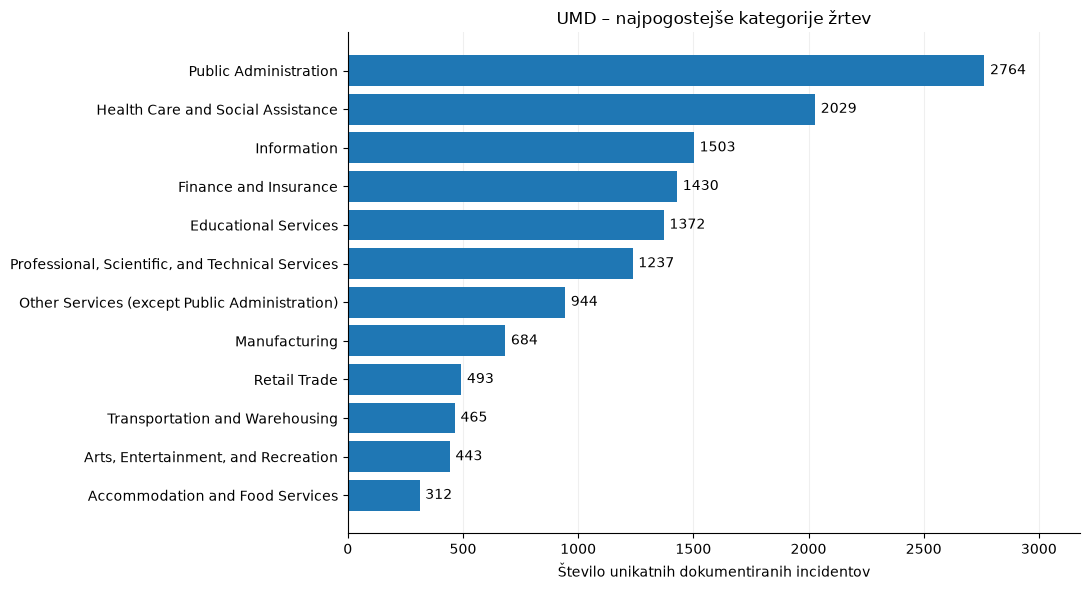

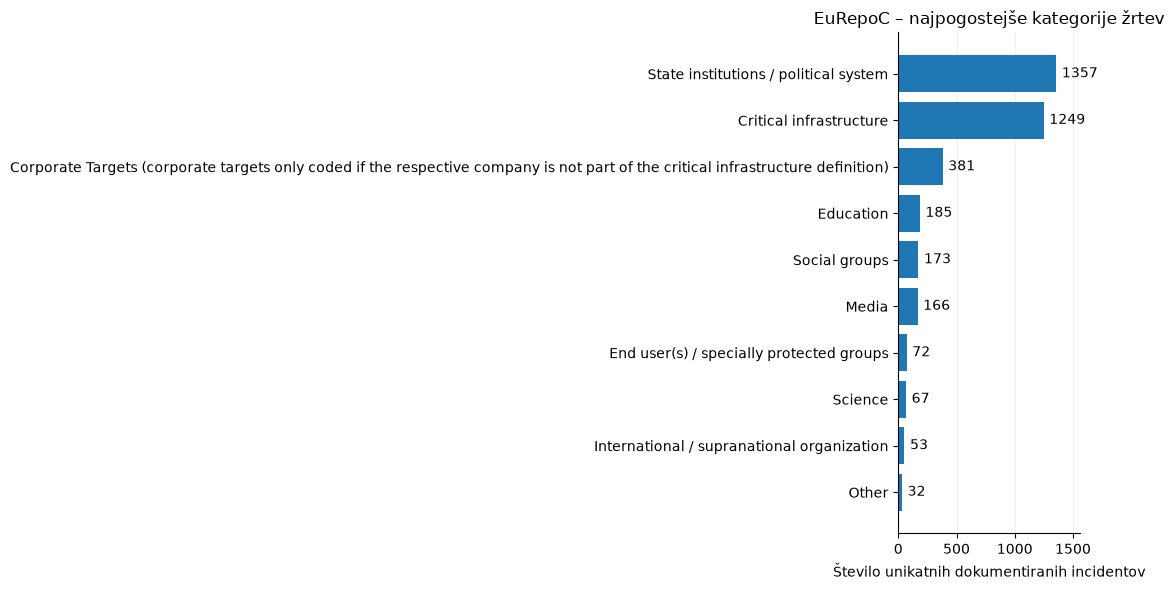

In [72]:
sector_sources = {
    "UMD": (
        umd_cov.loc[
            is_known(umd_cov["industry"])
        ].groupby("industry")["slug"].nunique()
    ),
    "EuRepoC": (
        eurepoc_cov.loc[
            is_known(eurepoc_cov["category"])
        ].groupby("category")["incident_id"].nunique()
    )
}

for source_name, counts in sector_sources.items():
    top = counts.sort_values(ascending=False).head(12)

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(
        top.index[::-1],
        top.values[::-1]
    )

    ax.bar_label(bars, padding=4)
    ax.set_xlim(0, top.max() * 1.15)
    ax.set_xlabel("Število unikatnih dokumentiranih incidentov")
    ax.set_title(f"{source_name} – najpogostejše kategorije žrtev")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()

In [73]:
eur_types = eurepoc_dates[
    eurepoc_dates["year"].between(2014, 2024)
].copy()

eur_types["incident_type"] = (
    eur_types["incident_type"]
    .astype("string")
    .str.split(";")
)

eur_types = eur_types.explode("incident_type")

eur_types["incident_type"] = (
    eur_types["incident_type"].str.strip()
)

eur_types = eur_types[
    is_known(eur_types["incident_type"])
].drop_duplicates(["incident_id", "incident_type"])

type_counts = (
    eur_types.groupby("incident_type")["incident_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(type_counts.to_frame("Incidenti"))

,Incidenti
incident_type,
Hijacking with Misuse,1668
Disruption,1170
Data theft,1012
Ransomware,492
Hijacking without Misuse,326
Data theft & Doxing,322


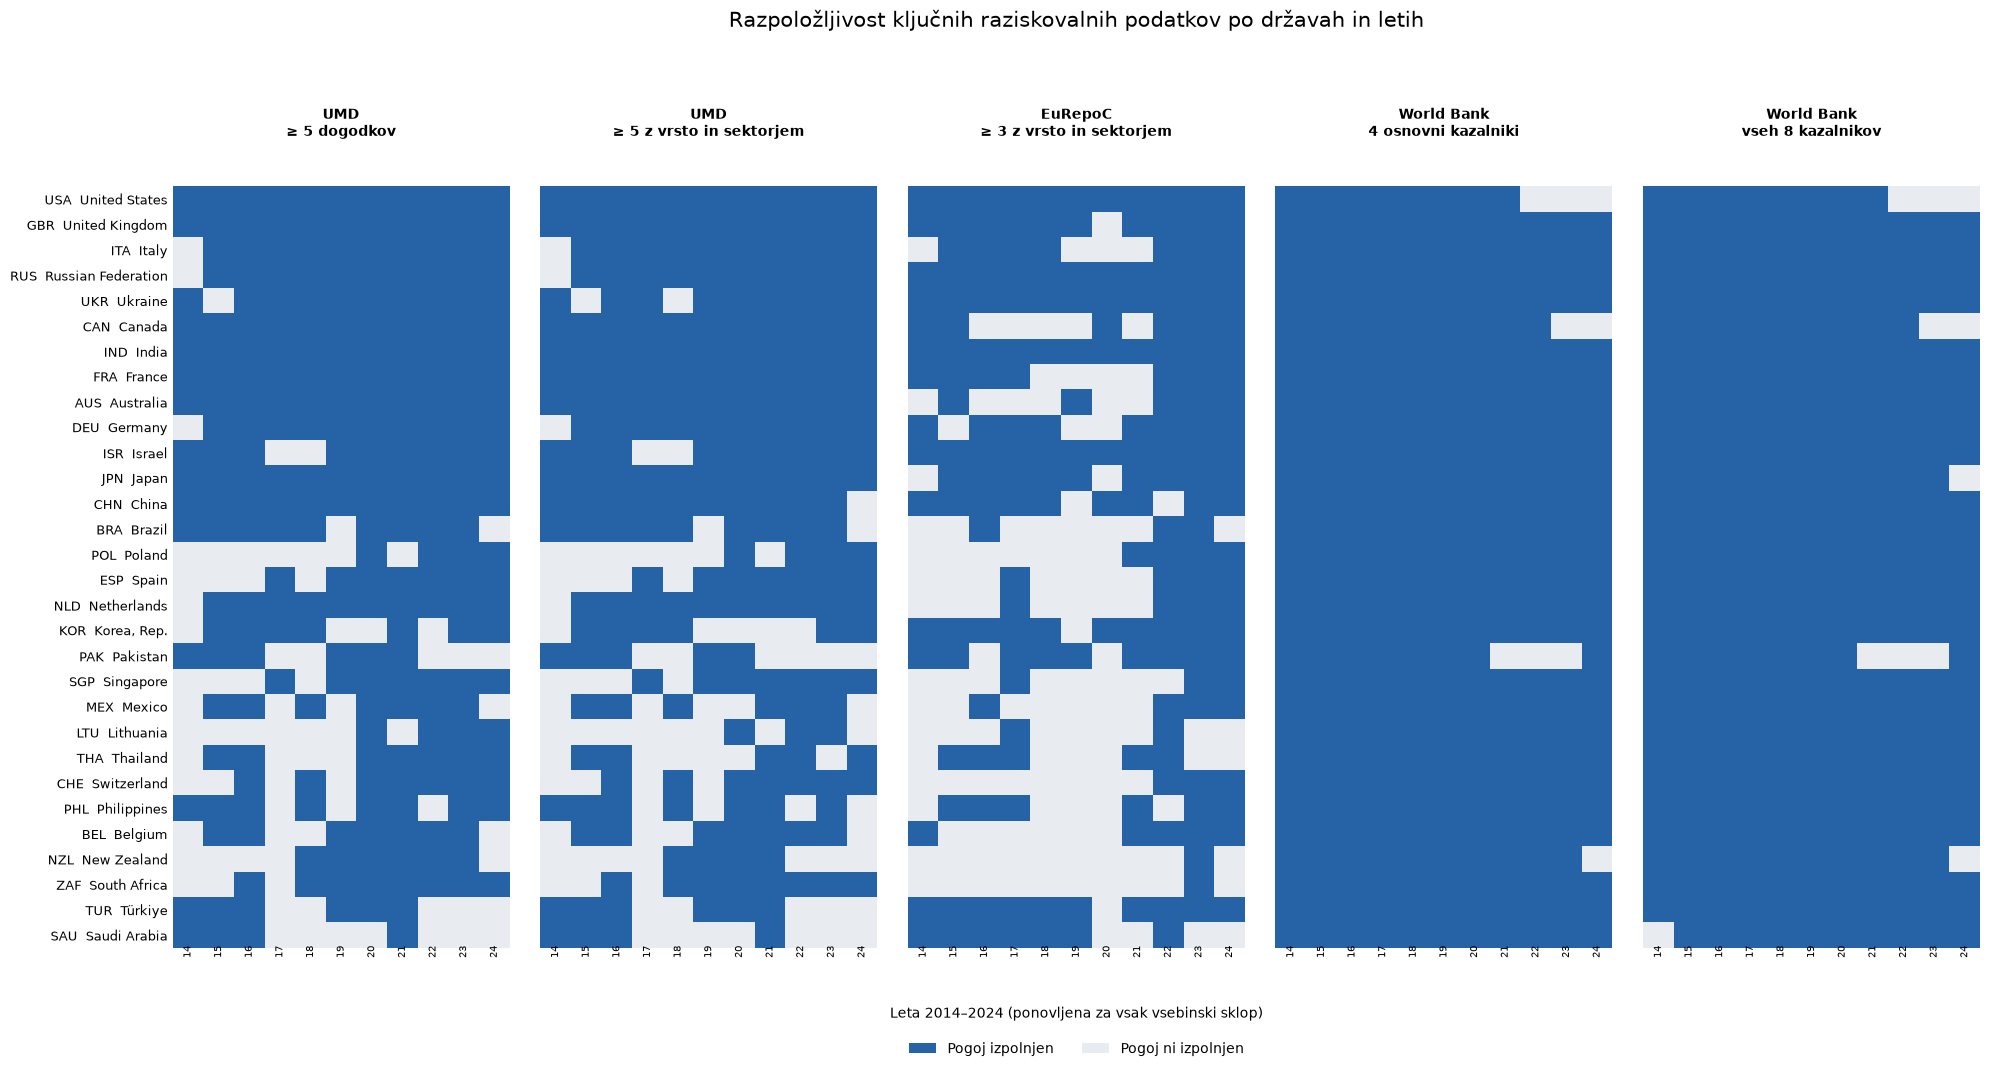

In [74]:
# Izbor največ 30 držav, ki imajo dovolj incidentov
# in osnovne gospodarske podatke.
selected = (
    summary2[
        (summary2["umd_incidents"] >= 30)
        & (summary2["wb_basic_years"] >= 5)
    ]
    .sort_values("umd_incidents", ascending=False)
    .head(30)
    .copy()
)

selected_iso3 = selected["iso3"].tolist()
names = selected.set_index("iso3")["country"].to_dict()

# Pomembno: obe značilnici morata biti znani
# pri ISTEM incidentu.
umd_both = (
    umd_cov[
        is_known(umd_cov["event_subtype"])
        & is_known(umd_cov["industry"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["slug"]
    .nunique()
)

eur_both = (
    eurepoc_cov[
        is_known(eurepoc_cov["incident_type"])
        & is_known(eurepoc_cov["category"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["incident_id"]
    .nunique()
)

# Pridružitev rezultatov obstoječi matriki
matrix_df = coverage2.copy()

for name, series in [
    ("umd_both", umd_both),
    ("eur_both", eur_both)
]:
    matrix_df[name] = (
        pd.MultiIndex.from_frame(matrix_df[["iso3", "year"]])
        .map(series)
    )
    matrix_df[name] = matrix_df[name].fillna(0).astype(int)

# Pogoji za pet vsebinskih skupin
conditions = {
    "UMD\n≥ 5 dogodkov":
        matrix_df["umd_incidents"] >= 5,

    "UMD\n≥ 5 z vrsto in sektorjem":
        matrix_df["umd_both"] >= 5,

    "EuRepoC\n≥ 3 z vrsto in sektorjem":
        matrix_df["eur_both"] >= 3,

    "World Bank\n4 osnovni kazalniki":
        matrix_df["wb_basic_available"] == 4,

    "World Bank\nvseh 8 kazalnikov":
        matrix_df["wb_available"] == 8
}

# Izdelava matrike prisotnosti (0 = ne, 1 = da)
blocks = []

for name, condition in conditions.items():
    temp = matrix_df.loc[
        matrix_df["iso3"].isin(selected_iso3),
        ["iso3", "year"]
    ].copy()

    temp["available"] = condition.loc[temp.index].astype(int)

    pivot = (
        temp.pivot(
            index="iso3",
            columns="year",
            values="available"
        )
        .reindex(index=selected_iso3, columns=YEARS)
        .fillna(0)
    )

    blocks.append(pivot.to_numpy())

# Med skupine vstavimo ozek prazen stolpec
plot_blocks = []
for i, block in enumerate(blocks):
    if i:
        plot_blocks.append(
            np.full((len(selected_iso3), 1), np.nan)
        )
    plot_blocks.append(block)

plot_matrix = np.concatenate(plot_blocks, axis=1)

cmap = ListedColormap(["#e8ecf0", "#2563a6"])
cmap.set_bad("white")

fig, ax = plt.subplots(
    figsize=(20, max(9, len(selected_iso3) * 0.36))
)

ax.imshow(
    np.ma.masked_invalid(plot_matrix),
    cmap=cmap,
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

block_width = len(YEARS) + 1

for i, name in enumerate(conditions):
    start = i * block_width
    center = start + (len(YEARS) - 1) / 2

    ax.text(
        center, -2.3, name,
        ha="center", va="bottom",
        fontsize=10, fontweight="bold"
    )

    # Leta prikazujemo v vsaki skupini
    for j, year in enumerate(YEARS):
        ax.text(
            start + j,
            len(selected_iso3) - 0.1,
            str(year)[-2:],
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90
        )

ax.set_yticks(range(len(selected_iso3)))
ax.set_yticklabels(
    [f"{code}  {names[code]}" for code in selected_iso3],
    fontsize=9
)

ax.set_xticks([])
ax.set_ylim(len(selected_iso3) + 1, -3.5)

ax.set_title(
    "Razpoložljivost ključnih raziskovalnih podatkov po državah in letih",
    fontsize=15,
    pad=60
)

ax.set_xlabel(
    "Leta 2014–2024 (ponovljena za vsak vsebinski sklop)",
    labelpad=15
)

ax.tick_params(axis="y", length=0)
ax.spines[:].set_visible(False)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(facecolor="#2563a6", label="Pogoj izpolnjen"),
        Patch(facecolor="#e8ecf0", label="Pogoj ni izpolnjen")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=2,
    frameon=False
)

plt.tight_layout()
plt.show()

In [75]:
# -----------------------------
# 1) Izbor držav za prikaz
# -----------------------------
# Lahko uporabiš selected_iso3, če že obstaja.
# Če ne, ga naredimo iz top držav po UMD.
if "selected_iso3" not in globals():
    selected_iso3 = (
        summary2.sort_values("umd_incidents", ascending=False)
        .head(30)["iso3"]
        .tolist()
    )

country_name_map = (
    country_summary.set_index("iso3")["country"].to_dict()
    if "country_summary" in globals()
    else {code: code for code in selected_iso3}
)

selected_labels = [
    f"{code}  {country_name_map.get(code, code)}"
    for code in selected_iso3
]

In [76]:
# -----------------------------
# 2) UMD: vsi incidenti
# -----------------------------
umd_counts = (
    umd_cov.dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["slug"]
    .nunique()
    .rename("umd_incidents")
)

In [77]:
# -----------------------------
# 3) UMD: incidenti z znano vrsto in sektorjem
# -----------------------------
umd_both = (
    umd_cov[
        is_known(umd_cov["event_subtype"])
        & is_known(umd_cov["industry"])
    ]
    .dropna(subset=["iso3"])
    .groupby(["iso3", "year"])["slug"]
    .nunique()
    .rename("umd_known_both")
)

In [78]:
# -----------------------------
# 4) EuRepoC: incidenti z znano vrsto in sektorjem
# -----------------------------
# incident_type iz EuRepoC Global po incident_id
eur_incident_type_known = (
    eurepoc_dates[["incident_id", "incident_type"]]
    .copy()
)

eur_incident_type_known["incident_type"] = (
    eur_incident_type_known["incident_type"]
    .astype("string")
    .str.strip()
)

eur_incident_type_known = eur_incident_type_known[
    is_known(eur_incident_type_known["incident_type"])
][["incident_id"]].drop_duplicates()

In [79]:
# Receiver zapisi z znano kategorijo
eur_receiver_known = (
    eurepoc_cov[
        is_known(eurepoc_cov["category"])
    ][["incident_id", "iso3", "year"]]
    .dropna(subset=["iso3"])
    .drop_duplicates()
)

In [80]:
# oboje skupaj
eur_both = (
    eur_receiver_known.merge(
        eur_incident_type_known,
        on="incident_id",
        how="inner"
    )
    .groupby(["iso3", "year"])["incident_id"]
    .nunique()
    .rename("eur_known_both")
)

In [81]:
# -----------------------------
# 5) World Bank: število razpoložljivih kazalnikov
# -----------------------------
wb_basic_codes = [
    "NY.GDP.PCAP.PP.KD",  # GDP per capita PPP
    "NV.IND.TOTL.ZS",     # Industry share
    "NV.SRV.TOTL.ZS",     # Services share
    "IT.NET.USER.ZS"      # Internet users
]

In [82]:
# coverage2 že vsebuje wb_basic_available in wb_available
wb_basic_avail = (
    coverage2.set_index(["iso3", "year"])["wb_basic_available"]
)

wb_all_avail = (
    coverage2.set_index(["iso3", "year"])["wb_available"]
)

In [83]:
# -----------------------------
# 6) Funkcija za pivot
# -----------------------------
def make_pivot(series, iso3_list, years, fill_value=0):
    idx = pd.MultiIndex.from_product(
        [iso3_list, years],
        names=["iso3", "year"]
    )
    s = series.reindex(idx, fill_value=fill_value)
    pivot = s.unstack("year")
    pivot = pivot.reindex(index=iso3_list, columns=years)
    return pivot

In [84]:
YEARS = list(range(2014, 2025))

p_umd = make_pivot(umd_counts, selected_iso3, YEARS)
p_umd_both = make_pivot(umd_both, selected_iso3, YEARS)
p_eur_both = make_pivot(eur_both, selected_iso3, YEARS)
p_wb4 = make_pivot(wb_basic_avail, selected_iso3, YEARS)
p_wb8 = make_pivot(wb_all_avail, selected_iso3, YEARS)

In [85]:
# -----------------------------
# 7) Funkcija za heatmap
# -----------------------------
def plot_heatmap(pivot, title, log_scale=False, annotate=False, fmt="{:.0f}"):
    data = pivot.copy()

    if log_scale:
        values = np.log1p(data.to_numpy(dtype=float))
        cbar_label = "log(1 + vrednost)"
    else:
        values = data.to_numpy(dtype=float)
        cbar_label = "vrednost"

    fig_height = max(8, len(data) * 0.33)
    fig, ax = plt.subplots(figsize=(14, fig_height))

    im = ax.imshow(values, aspect="auto", interpolation="nearest")

    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=90)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(
        [f"{iso3}  {country_name_map.get(iso3, iso3)}" for iso3 in data.index],
        fontsize=9
    )

    # mreža med celicami
    ax.set_xticks(np.arange(-.5, len(data.columns), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(data.index), 1), minor=True)
    ax.grid(which="minor", linestyle="-", linewidth=0.3)
    ax.tick_params(which="minor", bottom=False, left=False)

    cbar = fig.colorbar(im, ax=ax)

    if log_scale:
        ticks_actual = np.array([0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2000])

        ticks_actual = ticks_actual[
            np.log1p(ticks_actual) <= np.nanmax(values)
        ]

        cbar.set_ticks(np.log1p(ticks_actual))
        cbar.set_ticklabels([f"{x:,}" for x in ticks_actual])
        cbar.set_label("Dejansko število dokumentiranih incidentov")
    else:
        cbar.set_label(cbar_label)

    if annotate:
        raw = data.to_numpy()
        for i in range(raw.shape[0]):
            for j in range(raw.shape[1]):
                val = raw[i, j]
                if pd.notna(val) and val != 0:
                    ax.text(
                        j, i, fmt.format(val),
                        ha="center", va="center",
                        fontsize=6
                    )

    plt.tight_layout()
    plt.show()

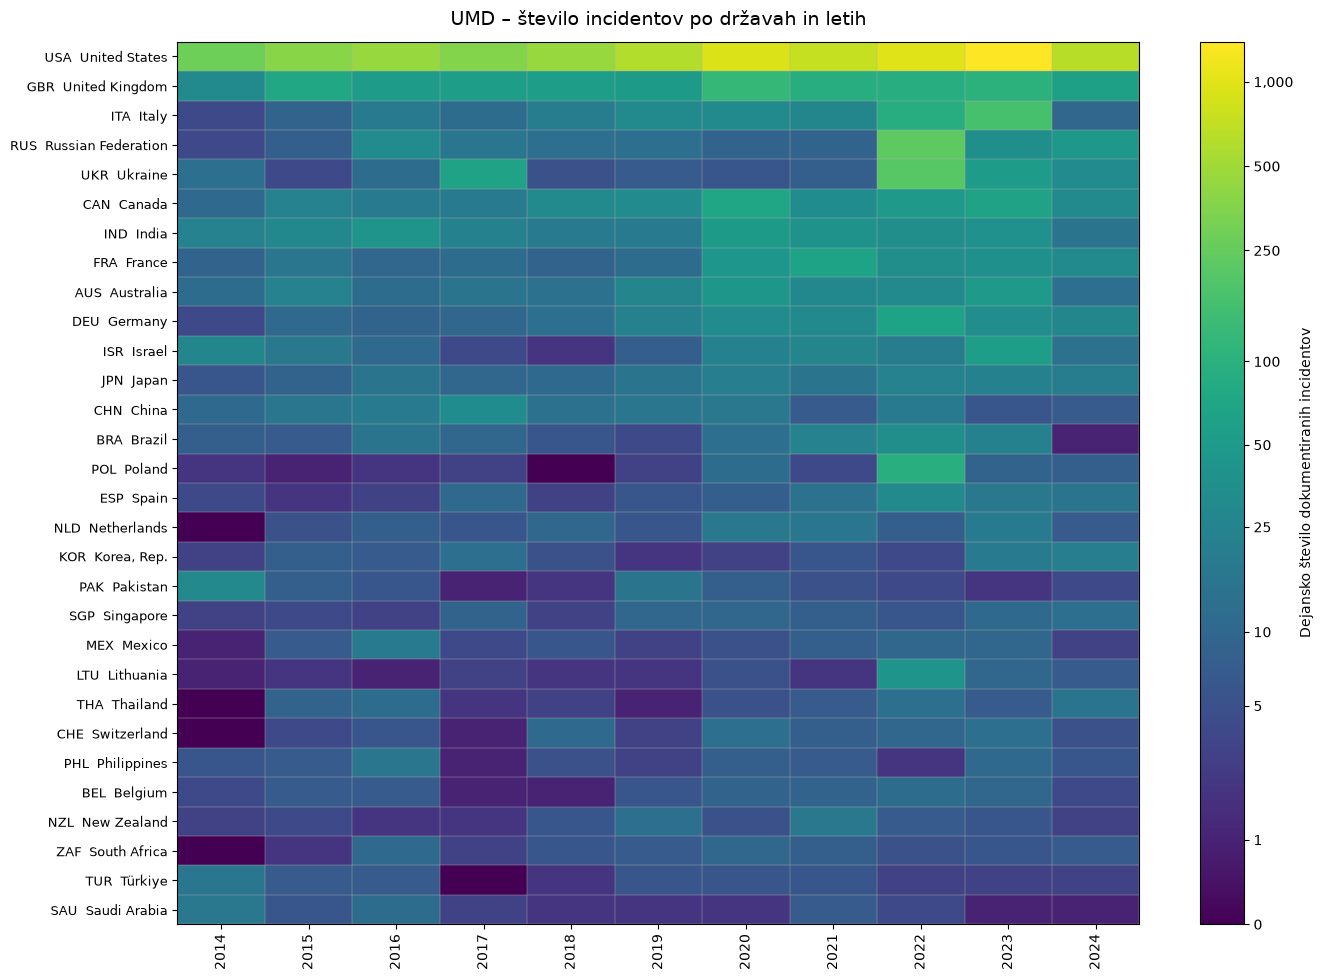

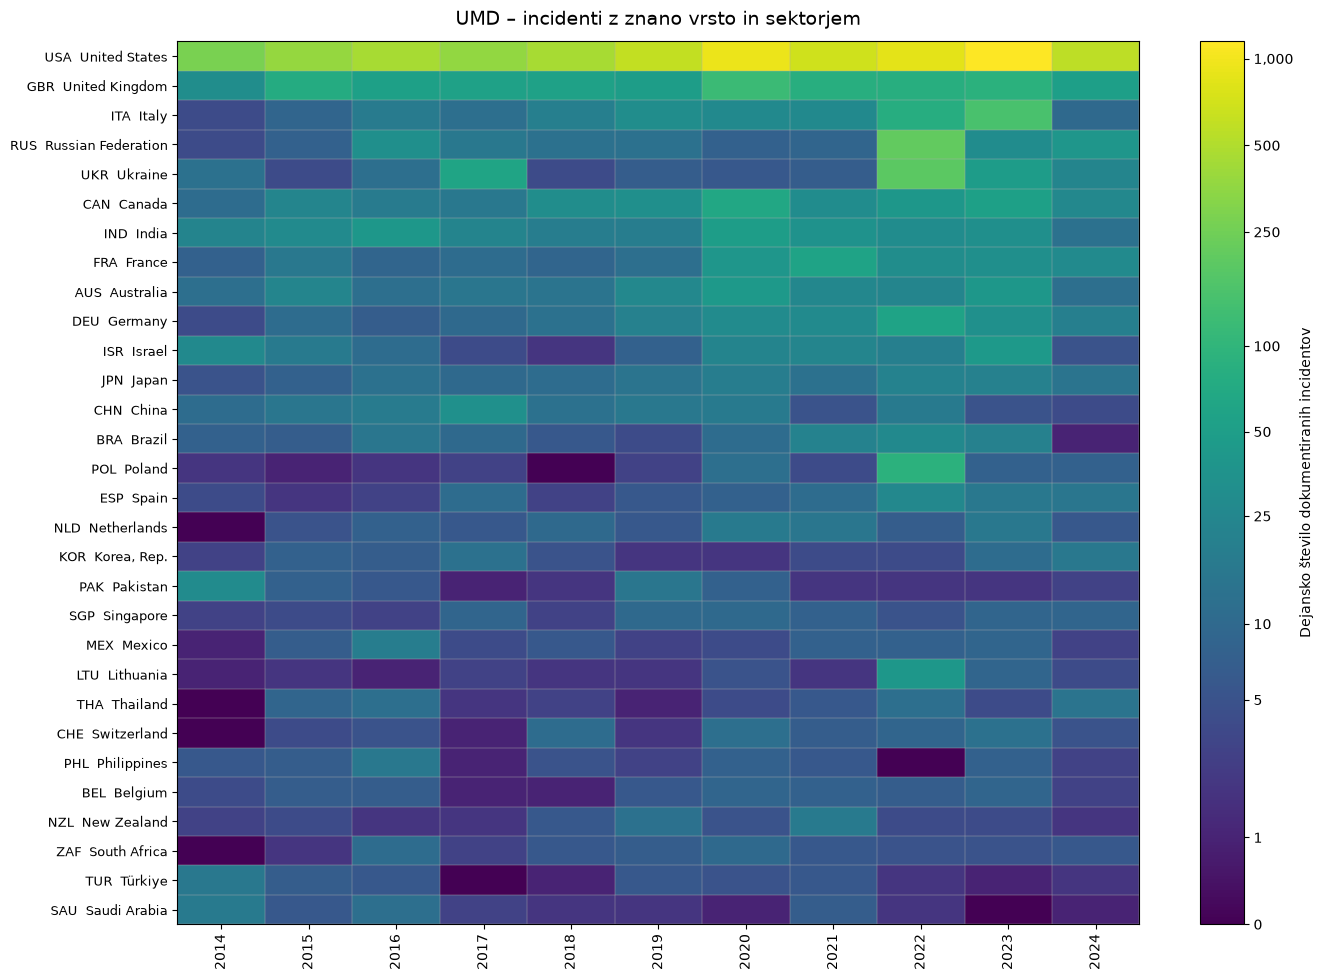

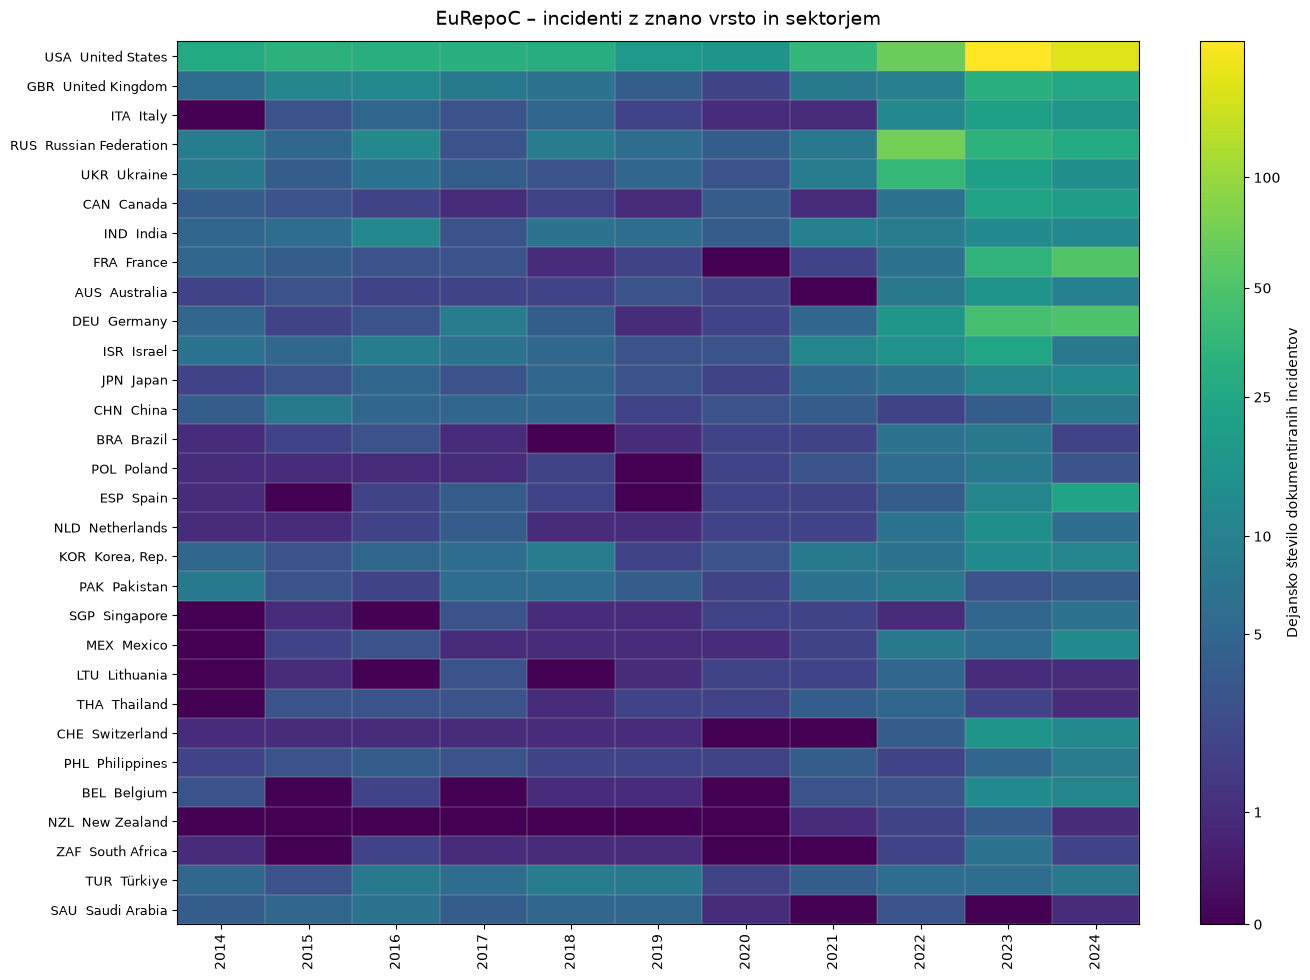

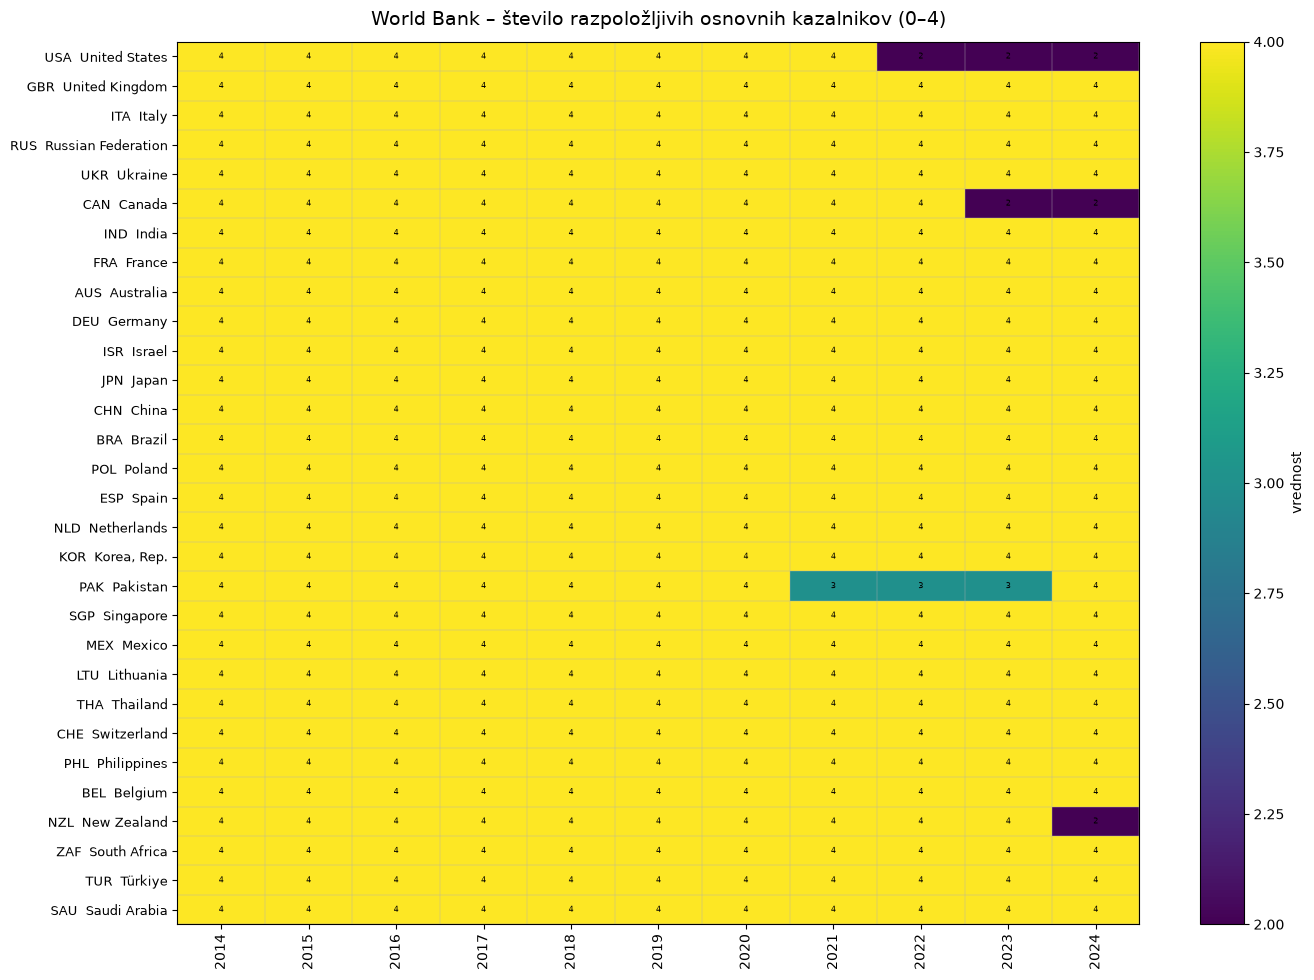

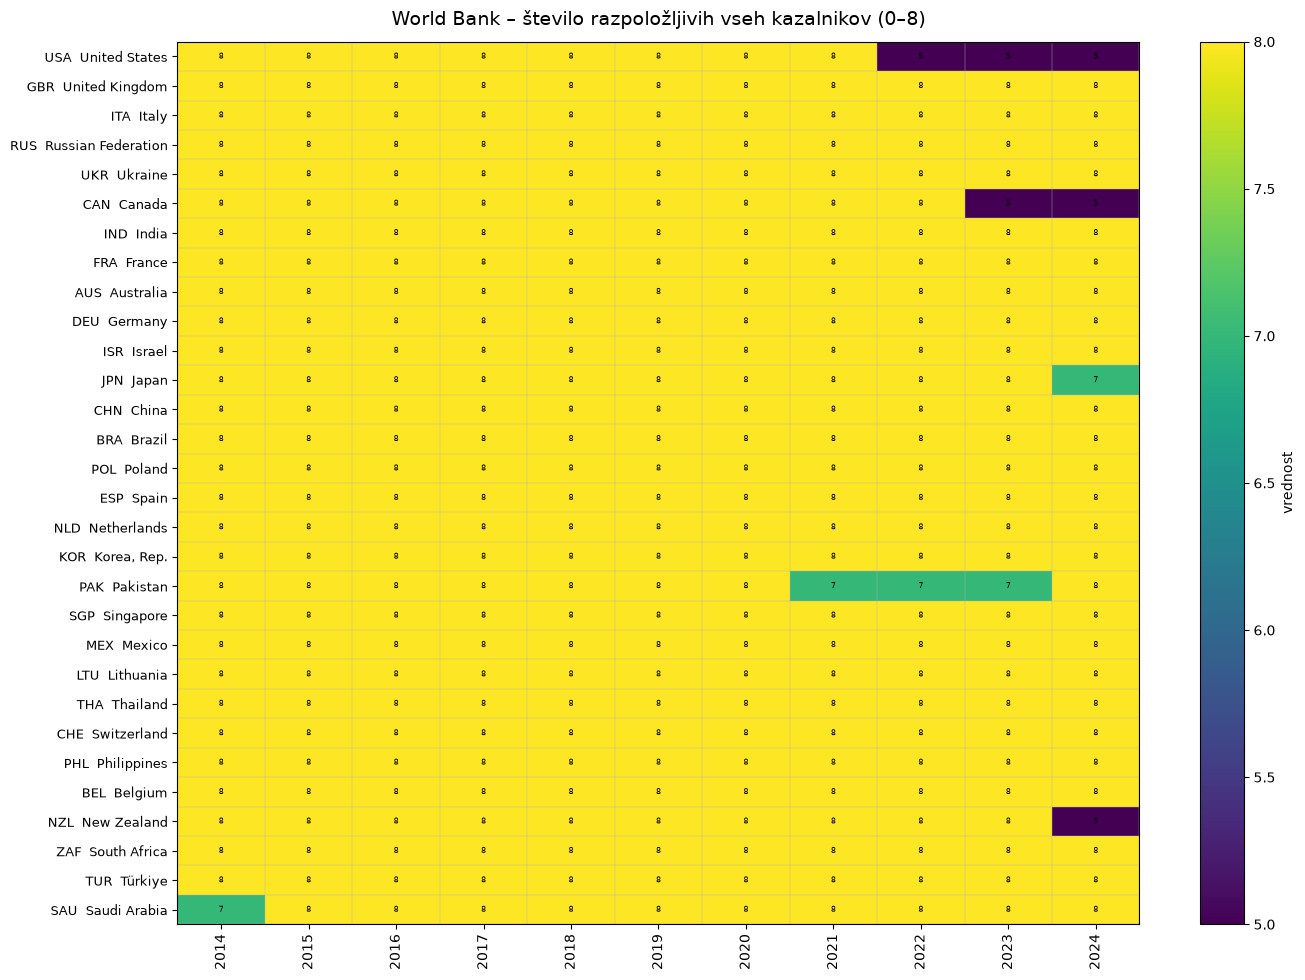

In [86]:
# -----------------------------
# 8) Risanje heatmap
# -----------------------------
plot_heatmap(
    p_umd,
    "UMD – število incidentov po državah in letih",
    log_scale=True,
    annotate=False
)

plot_heatmap(
    p_umd_both,
    "UMD – incidenti z znano vrsto in sektorjem",
    log_scale=True,
    annotate=False
)

plot_heatmap(
    p_eur_both,
    "EuRepoC – incidenti z znano vrsto in sektorjem",
    log_scale=True,
    annotate=False
)

plot_heatmap(
    p_wb4,
    "World Bank – število razpoložljivih osnovnih kazalnikov (0–4)",
    log_scale=False,
    annotate=True
)

plot_heatmap(
    p_wb8,
    "World Bank – število razpoložljivih vseh kazalnikov (0–8)",
    log_scale=False,
    annotate=True
)

Izbrane kazalnike

- BDP na prebivalca (PPP)	NY.GDP.PCAP.PP.KD

- Skupni BDP	NY.GDP.MKTP.CD
- Število prebivalcev	SP.POP.TOTL
- Delež industrije v BDP	NV.IND.TOTL.ZS
- Delež storitev v BDP	NV.SRV.TOTL.ZS
- Delež predelovalne industrije	NV.IND.MANF.ZS
- Delež uporabnikov interneta	IT.NET.USER.ZS
- Širokopasovne naročnine

In [87]:
selected_countries = ["USA", "CAN", "SVN"]
selected_years = [2022, 2023, 2024]

pregled_wb = wb_long[
    wb_long["Country Code"].isin(selected_countries)
    & wb_long["year"].isin(selected_years)
].copy()

pregled_wb["Status"] = np.where(
    pregled_wb["value"].notna(),
    "Na voljo",
    "Manjka"
)

display(
    pregled_wb.pivot_table(
        index=["Country Name", "Indicator Name"],
        columns="year",
        values="Status",
        aggfunc="first"
    )
)

year                                                                  2022  \
Country Name  Indicator Name                                                 
Canada        Fixed broadband subscriptions (per 100 people)      Na voljo   
              GDP (current US$)                                   Na voljo   
              GDP per capita, PPP (constant 2021 internationa...  Na voljo   
              Individuals using the Internet (% of population)    Na voljo   
              Industry (including construction), value added ...  Na voljo   
              Manufacturing, value added (% of GDP)               Na voljo   
              Population, total                                   Na voljo   
              Services, value added (% of GDP)                    Na voljo   
Slovenia      Fixed broadband subscriptions (per 100 people)      Na voljo   
              GDP (current US$)                                   Na voljo   
              GDP per capita, PPP (constant 2021 internationa...  Na voljo   
              Individuals using the Internet (% of population)    Na voljo   
              Industry (including construction), value added ...  Na voljo   
              Manufacturing, value added (% of GDP)               Na voljo   
              Population, total                                   Na voljo   
              Services, value added (% of GDP)                    Na voljo   
United States Fixed broadband subscriptions (per 100 people)      Na voljo   
              GDP (current US$)                                   Na voljo   
              GDP per capita, PPP (constant 2021 internationa...  Na voljo   
              Individuals using the Internet (% of population)    Na voljo   
              Industry (including construction), value added ...    Manjka   
              Manufacturing, value added (% of GDP)                 Manjka   
              Population, total                                   Na voljo   
              Services, value added (% of GDP)                      Manjka   

year                                                                  2023  \
Country Name  Indicator Name                                                 
Canada        Fixed broadband subscriptions (per 100 people)      Na voljo   
              GDP (current US$)                                   Na voljo   
              GDP per capita, PPP (constant 2021 internationa...  Na voljo   
              Individuals using the Internet (% of population)    Na voljo   
              Industry (including construction), value added ...    Manjka   
              Manufacturing, value added (% of GDP)                 Manjka   
              Population, total                                   Na voljo   
              Services, value added (% of GDP)                      Manjka   
Slovenia      Fixed broadband subscriptions (per 100 people)      Na voljo   
              GDP (current US$)                                   Na voljo   
              GDP per capita, PPP (constant 2021 internationa...  Na voljo   
              Individuals using the Internet (% of population)    Na voljo   
              Industry (including construction), value added ...  Na voljo   
              Manufacturing, value added (% of GDP)               Na voljo   
              Population, total                                   Na voljo   
              Services, value added (% of GDP)                    Na voljo   
United States Fixed broadband subscriptions (per 100 people)      Na voljo   
              GDP (current US$)                                   Na voljo   
              GDP per capita, PPP (constant 2021 internationa...  Na voljo   
              Individuals using the Internet (% of population)    Na voljo   
              Industry (including construction), value added ...    Manjka   
              Manufacturing, value added (% of GDP)                 Manjka   
              Population, total                                   Na voljo   
              Service